In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import polars.selectors as cs
import math
import seaborn as sns
from pathlib import Path

In [2]:
dataset_path = Path('../data/feret/OFIQ')
df_list = []

for f in sorted(dataset_path.iterdir()):
    if f.is_file() and f.suffix == '.csv':
        temp = pl.read_csv(f, separator=';')
        df_list.append(temp)

df = pl.concat(df_list, how='vertical_relaxed')
df.head(5)

Filename,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native,UnifiedQualityScore.scalar,BackgroundUniformity.scalar,IlluminationUniformity.scalar,LuminanceMean.scalar,LuminanceVariance.scalar,UnderExposurePrevention.scalar,OverExposurePrevention.scalar,DynamicRange.scalar,Sharpness.scalar,NoCompressionArtifacts.scalar,NaturalColour.scalar,SingleFacePresent.scalar,EyesOpen.scalar,MouthClosed.scalar,EyesVisible.scalar,MouthOcclusionPrevention.scalar,FaceOcclusionPrevention.scalar,InterEyeDistance.scalar,HeadSize.scalar,LeftwardCropOfFace.scalar,RightwardCropOfFace.scalar,MarginAboveTheFace.scalar,MarginBelowTheFace.scalar,HeadPoseYawFrontal.scalar,HeadPosePitchFrontal.scalar,HeadPoseRollFrontal.scalar,ExpressionNeutrality.scalar,NoHeadCoverings.scalar,assessment_time_in_ms,
str,f64,f64,f64,f64,f64,str,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""/home/vramos/prove/feret_all/i…",16.760118,25.646843,0.237654,0.130497,0.023341,"""0.379790""","""0.000301""",5.577375,23,0.994593,0.0,0.076084,0.037622,0.012371,0.098837,0.001256,0.168938,"""126.571378""",0.235358,3.490909,6.818182,1.626097,2.621667,-64.244137,-1.147325,3.250027,2455.544678,0.0,8,88,65,20,97,100,97,70,95,100,100,92,85,96,90,100,83,94,3,100,100,91,100,19,100,100,82,100,630,null
"""/home/vramos/prove/feret_all/i…",12.628016,47.431312,0.0,0.056781,0.008016,"""0.972388""","""0""",4.589491,35,0.985868,0.0,0.0,0.06801,0.246253,1.0,1.0,0.878718,"""nan""",0.198196,2.754368,4.284572,1.534723,3.523934,-90.0,2.044995,0.0,-1116.445312,0.461071,2,77,0,5,85,11,100,57,98,100,100,100,99,32,-1,0,12,-1,1,100,100,79,100,0,100,100,68,2,551,null
"""/home/vramos/prove/feret_all/i…",12.167166,118.707012,0.015625,0.085392,0.032919,"""0.999054""","""0.000036""",3.974379,19,0.99015,0.0,0.0,0.034246,0.077257,1.0,0.162239,0.210413,"""nan""",0.269664,3.814057,13.710876,1.308629,2.399958,-90.0,6.261364,0.0,888.375244,0.0,2,48,29,9,87,0,100,50,93,100,100,100,81,89,-1,84,79,-1,5,100,100,29,100,0,99,100,76,100,508,null
"""/home/vramos/prove/feret_all/i…",26.117825,70.761504,0.437098,0.14273,0.004033,"""0.259579""","""0.000015""",5.957399,33,0.997053,0.0,0.0,0.103142,0.006996,0.0,0.0,0.00343,"""111.933903""",0.263196,2.608317,3.126281,1.443196,2.365651,-15.008243,-7.187427,-0.535055,5207.723633,0.0,77,67,78,24,57,100,100,74,98,100,100,100,100,96,100,100,100,89,5,100,100,61,100,93,98,100,89,100,471,null
"""/home/vramos/prove/feret_all/i…",20.650282,106.955563,0.370983,0.225568,0.011244,"""0.083188""","""0.000039""",6.725002,47,0.997843,0.0,0.0,0.109179,0.004785,0.000964,0.0,0.078137,"""129.723109""",0.272146,2.412894,2.817797,1.47328,2.200353,-21.111168,-10.140567,-2.071783,4639.0,0.0,29,52,74,63,95,100,100,84,100,100,100,100,100,96,100,100,92,95,6,100,100,68,98,87,97,100,87,100,524,null


In [3]:
df = df.with_columns(
    pl.col([
        'UnifiedQualityScore.native',
        'UnderExposurePrevention.native',
        'OverExposurePrevention.native',
        'InterEyeDistance.native',
        'Sharpness.native'
    ]).cast(pl.Float64, strict=False)
)

In [4]:
df.select(pl.col(pl.Float32,pl.Float64).is_nan().sum())

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,3,3,0,0,0,0,0,0,0,0,0,0,485,0,0,0,0,0,0,0,0,0,0


#### Data cleaning

In [5]:
df = df.filter(
    ~pl.any_horizontal(pl.col(pl.Float32, pl.Float64).is_nan())\
)

In [6]:
df.select(pl.col(pl.Float32,pl.Float64).is_nan().sum())

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [7]:
df.head(5)

Filename,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native,UnifiedQualityScore.scalar,BackgroundUniformity.scalar,IlluminationUniformity.scalar,LuminanceMean.scalar,LuminanceVariance.scalar,UnderExposurePrevention.scalar,OverExposurePrevention.scalar,DynamicRange.scalar,Sharpness.scalar,NoCompressionArtifacts.scalar,NaturalColour.scalar,SingleFacePresent.scalar,EyesOpen.scalar,MouthClosed.scalar,EyesVisible.scalar,MouthOcclusionPrevention.scalar,FaceOcclusionPrevention.scalar,InterEyeDistance.scalar,HeadSize.scalar,LeftwardCropOfFace.scalar,RightwardCropOfFace.scalar,MarginAboveTheFace.scalar,MarginBelowTheFace.scalar,HeadPoseYawFrontal.scalar,HeadPosePitchFrontal.scalar,HeadPoseRollFrontal.scalar,ExpressionNeutrality.scalar,NoHeadCoverings.scalar,assessment_time_in_ms,
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""/home/vramos/prove/feret_all/i…",16.760118,25.646843,0.237654,0.130497,0.023341,0.37979,0.000301,5.577375,23.0,0.994593,0.0,0.076084,0.037622,0.012371,0.098837,0.001256,0.168938,126.571378,0.235358,3.490909,6.818182,1.626097,2.621667,-64.244137,-1.147325,3.250027,2455.544678,0.0,8,88,65,20,97,100,97,70,95,100,100,92,85,96,90,100,83,94,3,100,100,91,100,19,100,100,82,100,630,null
"""/home/vramos/prove/feret_all/i…",26.117825,70.761504,0.437098,0.14273,0.004033,0.259579,0.000015,5.957399,33.0,0.997053,0.0,0.0,0.103142,0.006996,0.0,0.0,0.00343,111.933903,0.263196,2.608317,3.126281,1.443196,2.365651,-15.008243,-7.187427,-0.535055,5207.723633,0.0,77,67,78,24,57,100,100,74,98,100,100,100,100,96,100,100,100,89,5,100,100,61,100,93,98,100,89,100,471,null
"""/home/vramos/prove/feret_all/i…",20.650282,106.955563,0.370983,0.225568,0.011244,0.083188,0.000039,6.725002,47.0,0.997843,0.0,0.0,0.109179,0.004785,0.000964,0.0,0.078137,129.723109,0.272146,2.412894,2.817797,1.47328,2.200353,-21.111168,-10.140567,-2.071783,4639.0,0.0,29,52,74,63,95,100,100,84,100,100,100,100,100,96,100,100,92,95,6,100,100,68,98,87,97,100,87,100,524,null
"""/home/vramos/prove/feret_all/i…",23.76329,31.39445,0.652778,0.087729,0.001029,0.691631,0.0,4.953324,0.0,0.989652,0.0,0.0,0.102304,0.083526,0.0,0.0,0.006801,129.414887,0.281034,2.37319,2.623,1.453552,2.11299,-8.181852,2.911887,3.721124,-12382.645508,0.0,57,85,88,10,18,99,100,62,77,100,100,100,100,87,100,100,99,95,7,100,100,63,96,98,100,100,19,100,519,null
"""/home/vramos/prove/feret_all/i…",23.447203,84.5078,0.191919,0.106425,0.004081,0.456318,0.0,5.804844,39.0,0.993326,0.0,0.0,0.082547,0.005743,0.007738,0.0,0.101598,133.334615,0.320633,2.523492,2.539363,1.417283,1.701552,19.071781,5.608222,0.672989,9588.507812,0.0,54,61,61,13,58,100,100,73,99,100,100,100,100,96,99,100,90,96,14,100,100,54,27,89,99,100,95,100,574,null


In [8]:
native = df.select(cs.ends_with('.native'))
scalar = df.select(cs.ends_with('.scalar'))

#### Data distribution

In [9]:
def create_histograms(df, n_cols=4, bins=40, clip=(1, 99), drop_errors=True):
    n_rows = math.ceil(df.shape[1] / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
    axes = np.array(axes).flatten()

    for ax, name in zip(axes, df.columns):
        values = df[name].drop_nulls().to_numpy().astype(float)
        values = values[~np.isnan(values)]
        if drop_errors:
            values = values[values != -1]          
        if len(values) == 0:
            ax.set_title(f"{name} (vuota)")
            continue
        lo, hi = np.percentile(values, clip)
        if lo == hi:                              
            lo, hi = values.min(), values.max() + 1e-9
        ax.hist(values, bins=bins, range=(lo, hi), edgecolor="white", linewidth=0.4)
        ax.set_title(name, fontsize=9)

    for ax in axes[len(df.columns):]:
        ax.set_visible(False)                

    fig.tight_layout()
    return fig

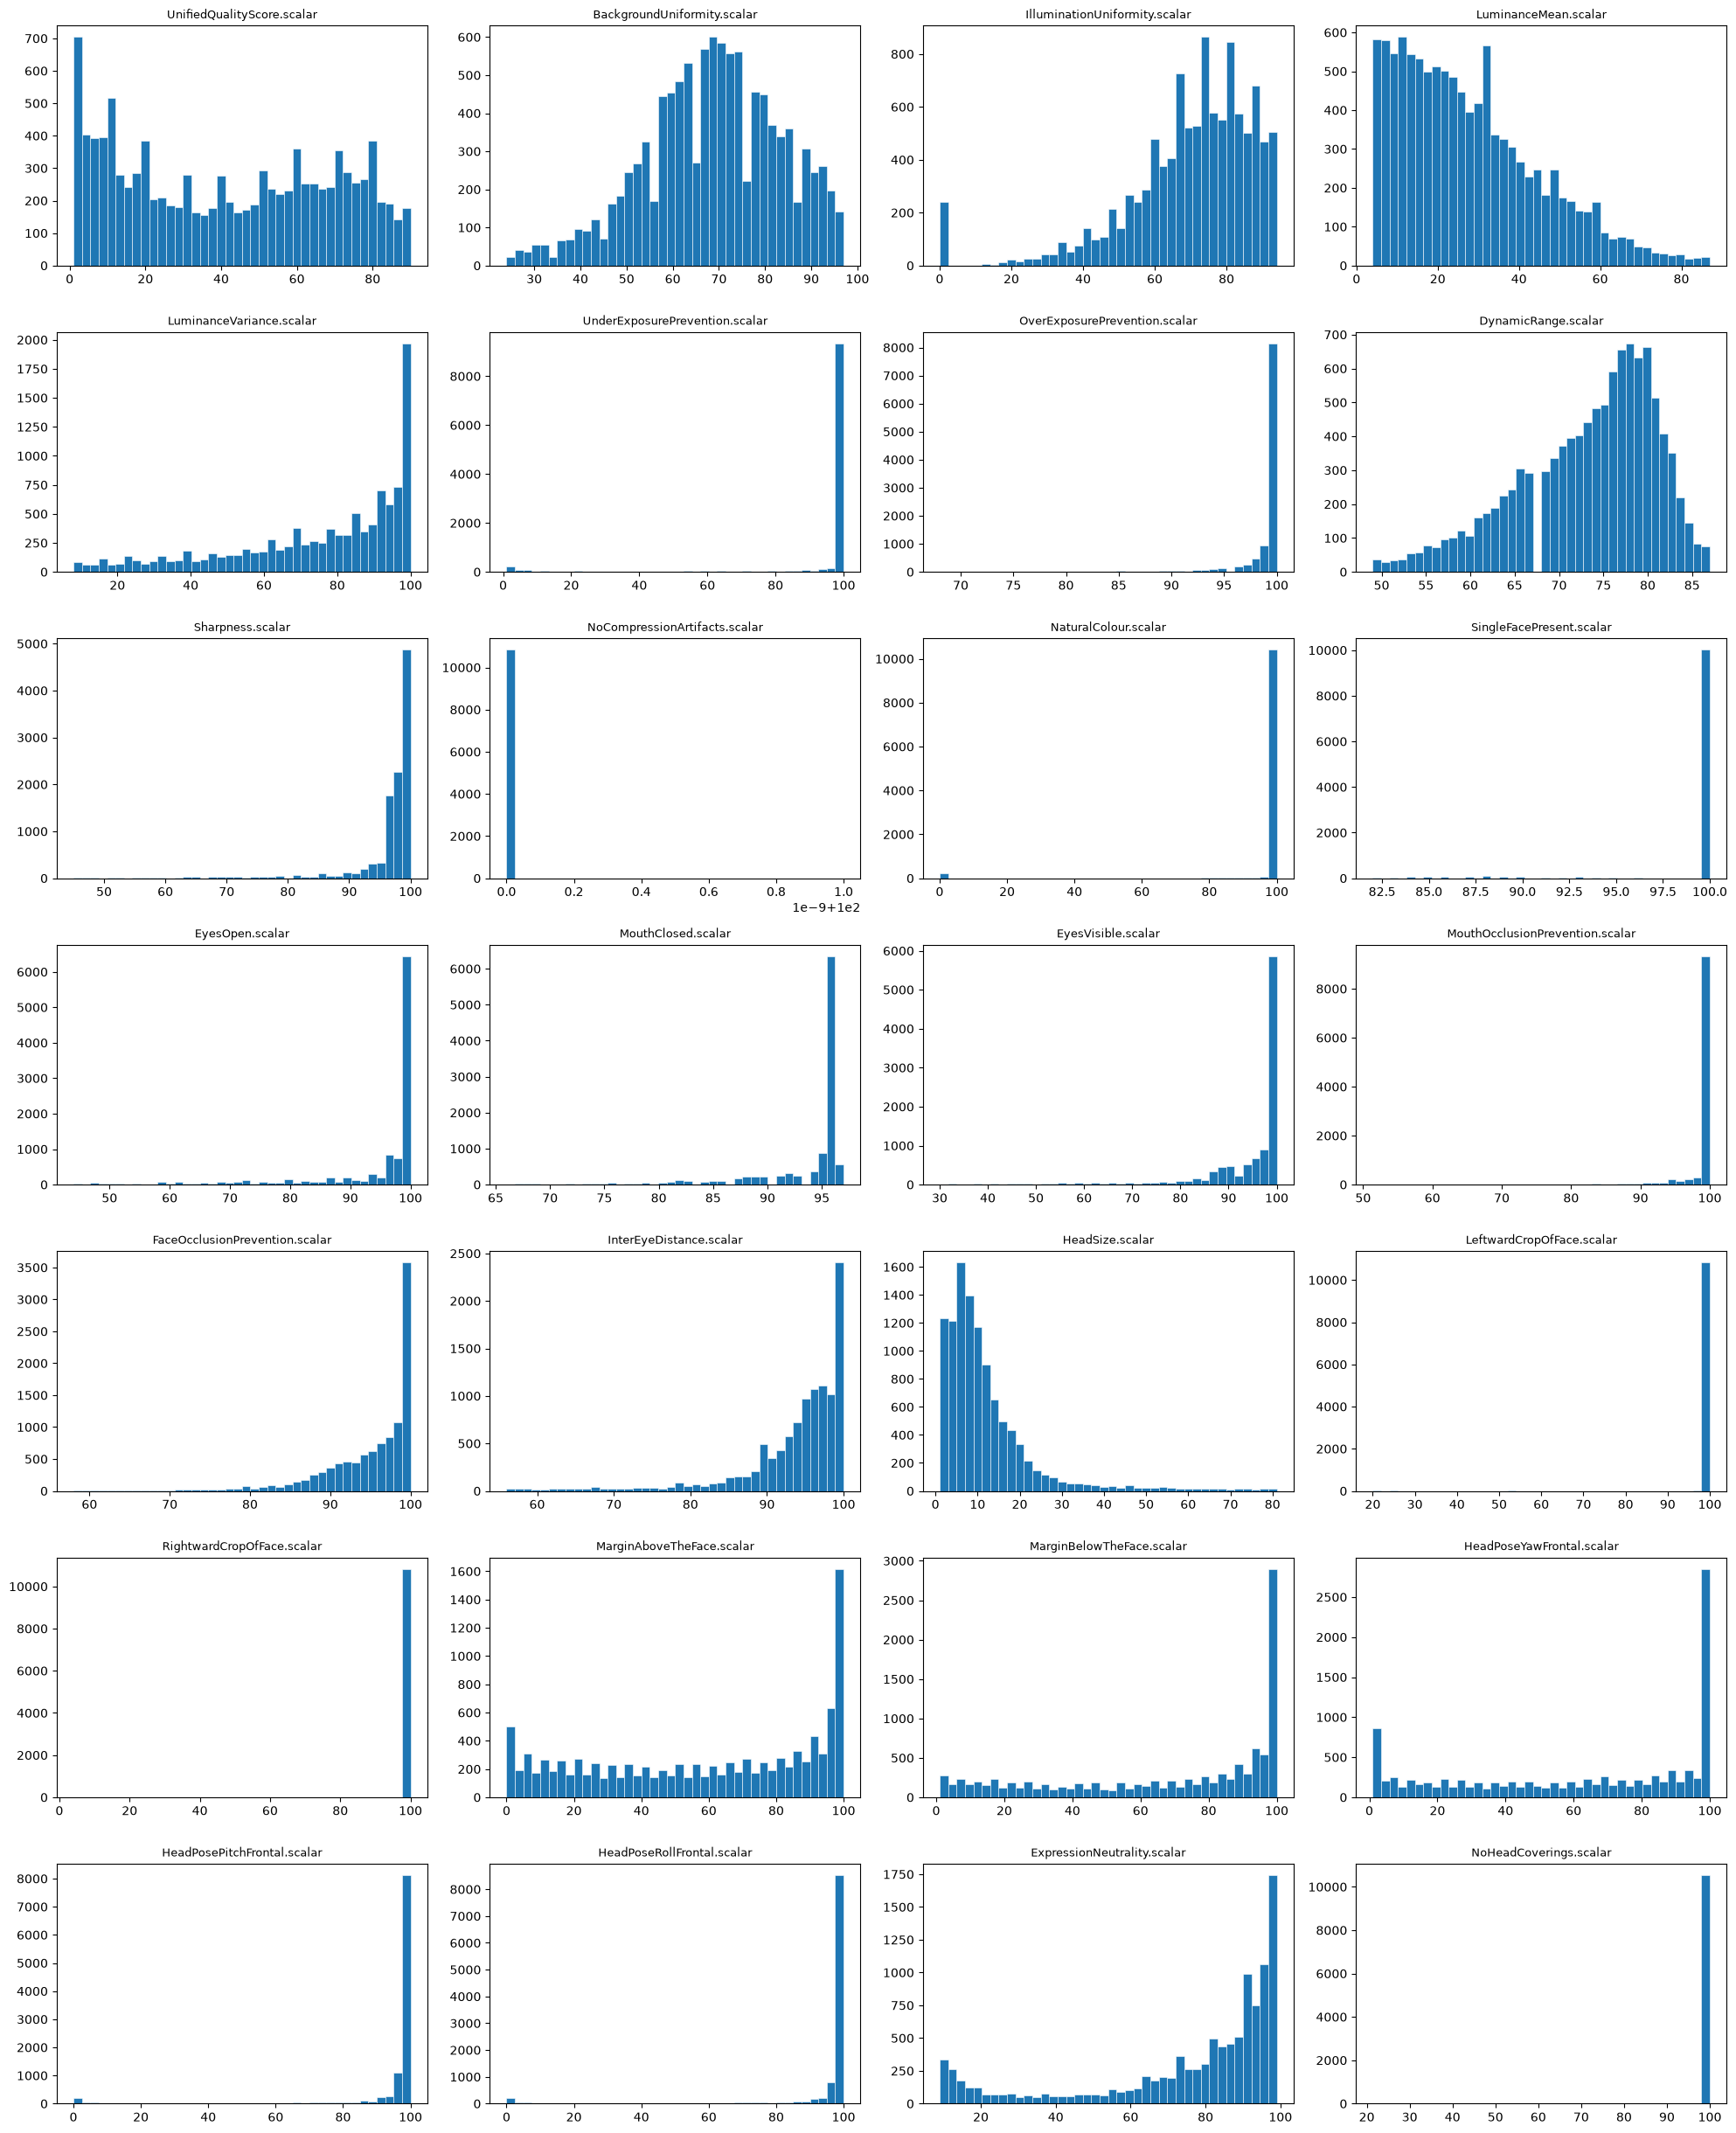

In [10]:
create_histograms(scalar);

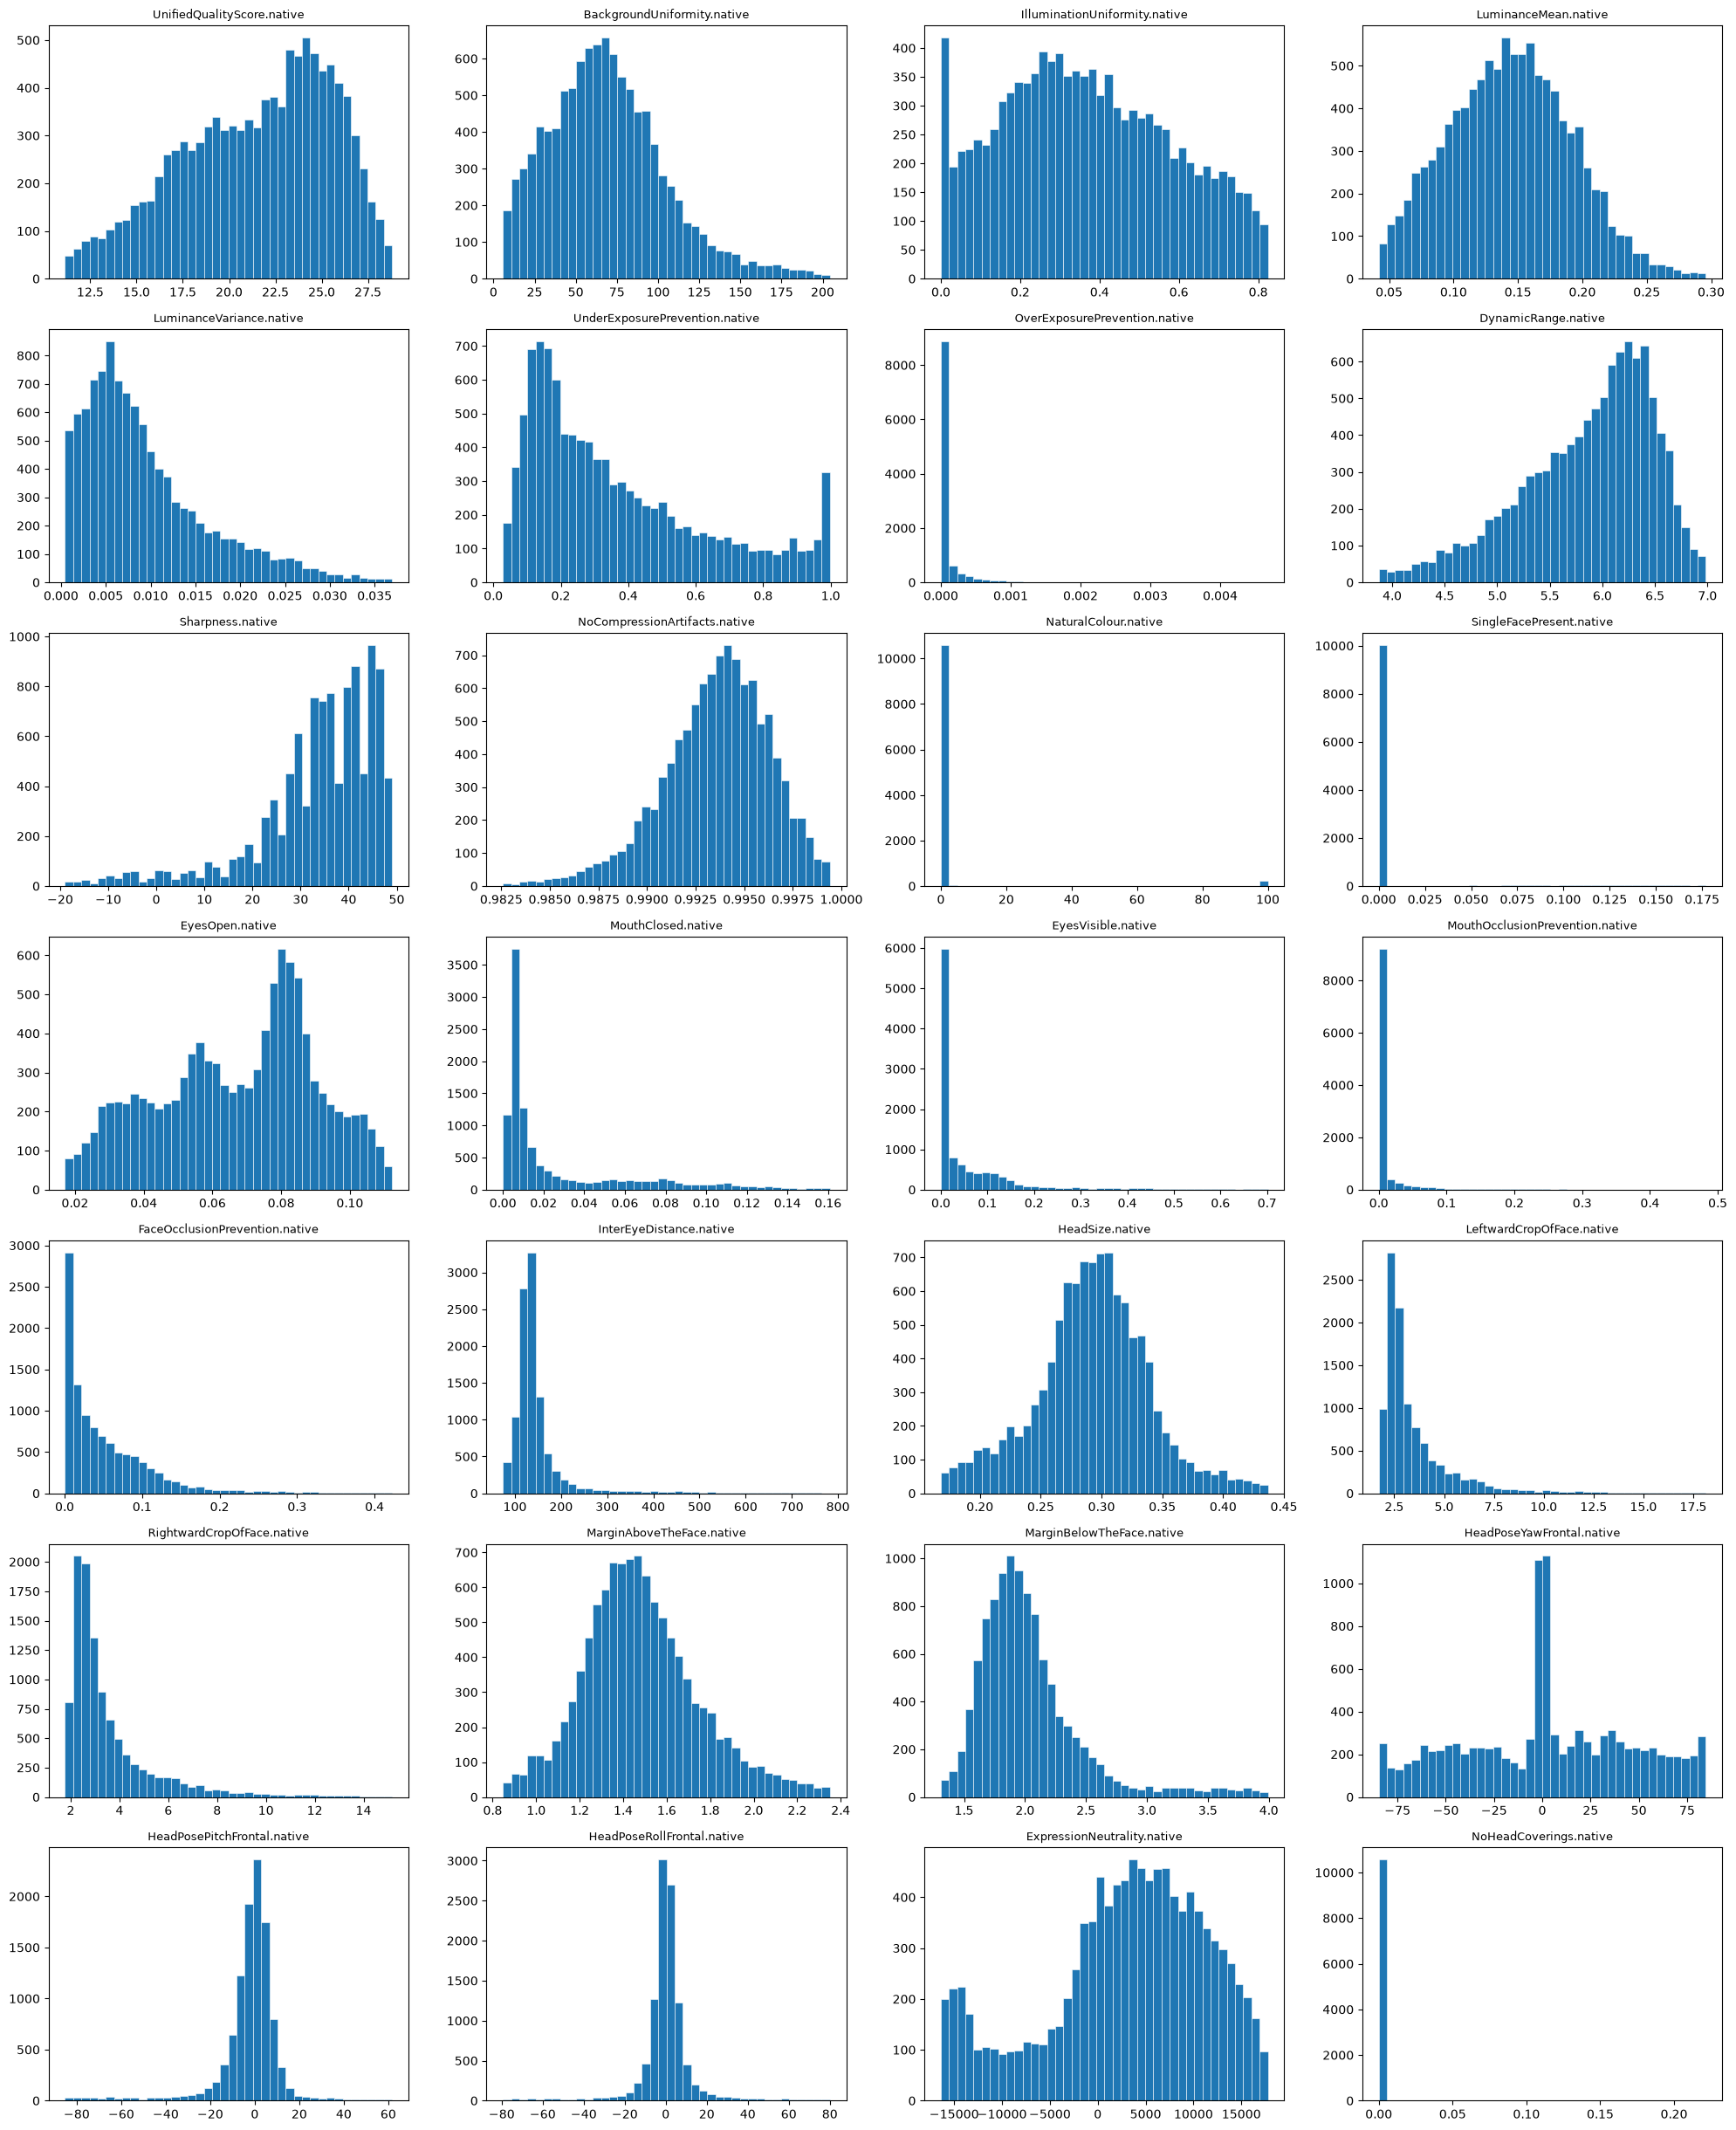

In [11]:
create_histograms(native);

#### Mean and Variabilty of the data

In [12]:
df_describe = native.describe()
mean = df_describe.filter(pl.col('statistic') == 'mean')
median = df_describe.filter(pl.col('statistic') == '50%')

In [13]:
df_describe

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0,10850.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",21.417057,70.61044,0.372547,0.145426,0.009784,0.369889,0.000298,5.841781,32.849862,0.992525,1.987283,0.0099,0.067206,0.03113,0.067084,0.019048,0.059201,158.855586,0.292297,3.776976,3.722817,1.484961,2.0503,2.092131,-2.485607,0.266249,2951.416148,0.004974
"""std""",4.291874,42.106777,0.217238,0.054446,0.008568,0.267518,0.005391,0.694411,14.143792,0.030358,13.809553,0.03802,0.024027,0.063907,0.133849,0.08973,0.086539,132.789667,0.052307,3.524171,2.8915,0.297062,0.496637,44.503017,19.256842,19.372137,8686.561533,0.04264
"""min""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-49.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-85.938852,-122.3133,-132.573497,-18602.507812,0.0
"""25%""",18.379166,43.198886,0.203125,0.10846,0.004283,0.155387,0.0,5.449988,28.0,0.991885,0.0,0.0,0.049578,0.004913,0.0,0.0,0.00919,118.638693,0.264975,2.38064,2.400506,1.302038,1.75931,-31.060407,-5.658165,-3.435812,-1571.379883,0.0
"""50%""",22.069786,66.04818,0.355372,0.143761,0.007549,0.287856,0.0,5.988428,36.0,0.993805,0.0,0.0,0.071074,0.00926,0.005536,0.0,0.034003,131.89047,0.293406,2.796868,2.860223,1.456925,1.94659,0.785737,-0.348478,0.107613,4021.830566,0.0
"""75%""",24.776773,90.398125,0.534722,0.177445,0.012873,0.522348,0.000049,6.340381,43.0,0.995508,0.0,0.0,0.084484,0.039269,0.081904,0.0,0.079833,149.907305,0.321629,3.902482,3.962936,1.638682,2.187516,35.169892,4.049491,3.996033,9410.082031,0.0
"""max""",31.875357,710.325711,0.96,0.625395,0.162179,1.0,0.491325,7.333203,50.0,1.00572,100.0,0.726442,0.314696,1.510594,1.0,1.0,0.995528,2971.227274,0.732378,74.943508,110.662689,3.570034,5.112547,85.942518,145.82424,121.877584,20568.119141,0.957704


In [14]:
mean

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""mean""",21.417057,70.61044,0.372547,0.145426,0.009784,0.369889,0.000298,5.841781,32.849862,0.992525,1.987283,0.0099,0.067206,0.03113,0.067084,0.019048,0.059201,158.855586,0.292297,3.776976,3.722817,1.484961,2.0503,2.092131,-2.485607,0.266249,2951.416148,0.004974


In [15]:
median

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""50%""",22.069786,66.04818,0.355372,0.143761,0.007549,0.287856,0.0,5.988428,36.0,0.993805,0.0,0.0,0.071074,0.00926,0.005536,0.0,0.034003,131.89047,0.293406,2.796868,2.860223,1.456925,1.94659,0.785737,-0.348478,0.107613,4021.830566,0.0


In [16]:
for c1, c2 in zip(mean.columns, median.columns):
    print(f"Column {c1}")
    print(f"Mean: {mean[c1].to_numpy().item()}")
    print(f"Median: {median[c1].to_numpy().item()}")
    print("==============")

Column statistic
Mean: mean
Median: 50%
Column UnifiedQualityScore.native
Mean: 21.41705730046083
Median: 22.069786
Column BackgroundUniformity.native
Mean: 70.61044045023041
Median: 66.04818
Column IlluminationUniformity.native
Mean: 0.37254711253456224
Median: 0.355372
Column LuminanceMean.native
Mean: 0.14542555069124424
Median: 0.143761
Column LuminanceVariance.native
Mean: 0.009784242211981566
Median: 0.007549
Column UnderExposurePrevention.native
Mean: 0.36988919612903226
Median: 0.287856
Column OverExposurePrevention.native
Mean: 0.0002978908755760369
Median: 0.0
Column DynamicRange.native
Mean: 5.841781243410138
Median: 5.988428
Column Sharpness.native
Mean: 32.849861751152076
Median: 36.0
Column NoCompressionArtifacts.native
Mean: 0.9925253535483871
Median: 0.993805
Column NaturalColour.native
Mean: 1.987283401013825
Median: 0.0
Column SingleFacePresent.native
Mean: 0.009900432258064517
Median: 0.0
Column EyesOpen.native
Mean: 0.06720554119815667
Median: 0.071074
Column MouthC

In [17]:
distance = df_describe.select(
    cs.numeric().filter(pl.col("statistic") == "max").first()
    - cs.numeric().filter(pl.col("statistic") == "min").first()
)

for col in distance.columns:
    print(col)
    print(f"Distanza: {distance[col].to_numpy().item()}")
    print("============")

UnifiedQualityScore.native
Distanza: 31.875357
BackgroundUniformity.native
Distanza: 710.325711
IlluminationUniformity.native
Distanza: 0.96
LuminanceMean.native
Distanza: 0.625395
LuminanceVariance.native
Distanza: 0.162179
UnderExposurePrevention.native
Distanza: 1.0
OverExposurePrevention.native
Distanza: 0.491325
DynamicRange.native
Distanza: 7.333203
Sharpness.native
Distanza: 99.0
NoCompressionArtifacts.native
Distanza: 1.00572
NaturalColour.native
Distanza: 100.0
SingleFacePresent.native
Distanza: 0.726442
EyesOpen.native
Distanza: 0.314696
MouthClosed.native
Distanza: 1.510594
EyesVisible.native
Distanza: 1.0
MouthOcclusionPrevention.native
Distanza: 1.0
FaceOcclusionPrevention.native
Distanza: 0.995528
InterEyeDistance.native
Distanza: 2971.227274
HeadSize.native
Distanza: 0.732378
LeftwardCropOfFace.native
Distanza: 74.943508
RightwardCropOfFace.native
Distanza: 110.662689
MarginAboveTheFace.native
Distanza: 3.570034
MarginBelowTheFace.native
Distanza: 5.112547
HeadPoseYawFro

In [18]:
std = df_describe.filter(pl.col('statistic') == 'std')

for col in std.columns:
    print(col)
    print(f"Varianza: {std[col].to_numpy().item()}")
    print("========================")

statistic
Varianza: std
UnifiedQualityScore.native
Varianza: 4.291874127744955
BackgroundUniformity.native
Varianza: 42.10677742103401
IlluminationUniformity.native
Varianza: 0.2172384269635281
LuminanceMean.native
Varianza: 0.05444582910156978
LuminanceVariance.native
Varianza: 0.008568262578391573
UnderExposurePrevention.native
Varianza: 0.26751789268290993
OverExposurePrevention.native
Varianza: 0.005390661673997887
DynamicRange.native
Varianza: 0.6944107684033207
Sharpness.native
Varianza: 14.143792410352013
NoCompressionArtifacts.native
Varianza: 0.030357798680165932
NaturalColour.native
Varianza: 13.809553144881031
SingleFacePresent.native
Varianza: 0.038019626374200005
EyesOpen.native
Varianza: 0.024026938616714587
MouthClosed.native
Varianza: 0.06390723723396448
EyesVisible.native
Varianza: 0.13384852722561752
MouthOcclusionPrevention.native
Varianza: 0.08972998602379074
FaceOcclusionPrevention.native
Varianza: 0.08653919150771681
InterEyeDistance.native
Varianza: 132.789667257

In [19]:
def whisker_and_box_diagram(df):
    col = 4

    numeric_columns = [
        name for name in df.columns
        if df[name].dtype.is_numeric()
    ]
    row = math.ceil(len(numeric_columns) / col)
    fig, ax = plt.subplots(row, col, figsize=(20, 4 * row))
    ax = np.array(ax).flatten()

    for i, name in enumerate(numeric_columns):
        column = df[name].drop_nulls().to_numpy()

        if len(column) == 0:
            continue

        q1 = np.percentile(column, 25)
        med = np.percentile(column, 50)
        q3 = np.percentile(column, 75)

        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        fliers = column[
            (column < lower_limit) | (column > upper_limit)
        ]

        whislo = np.min(column[column >= lower_limit])
        whishi = np.max(column[column <= upper_limit])

        plt_data = [{
            'label': "",
            'whislo': whislo,
            'q1': q1,
            'med': med,
            'q3': q3,
            'whishi': whishi,
            'fliers': fliers
        }]

        ax[i].bxp(plt_data, orientation="horizontal")
        ax[i].set_title(name)
    for i in range(len(numeric_columns), len(ax)):
        fig.delaxes(ax[i])
    plt.show()

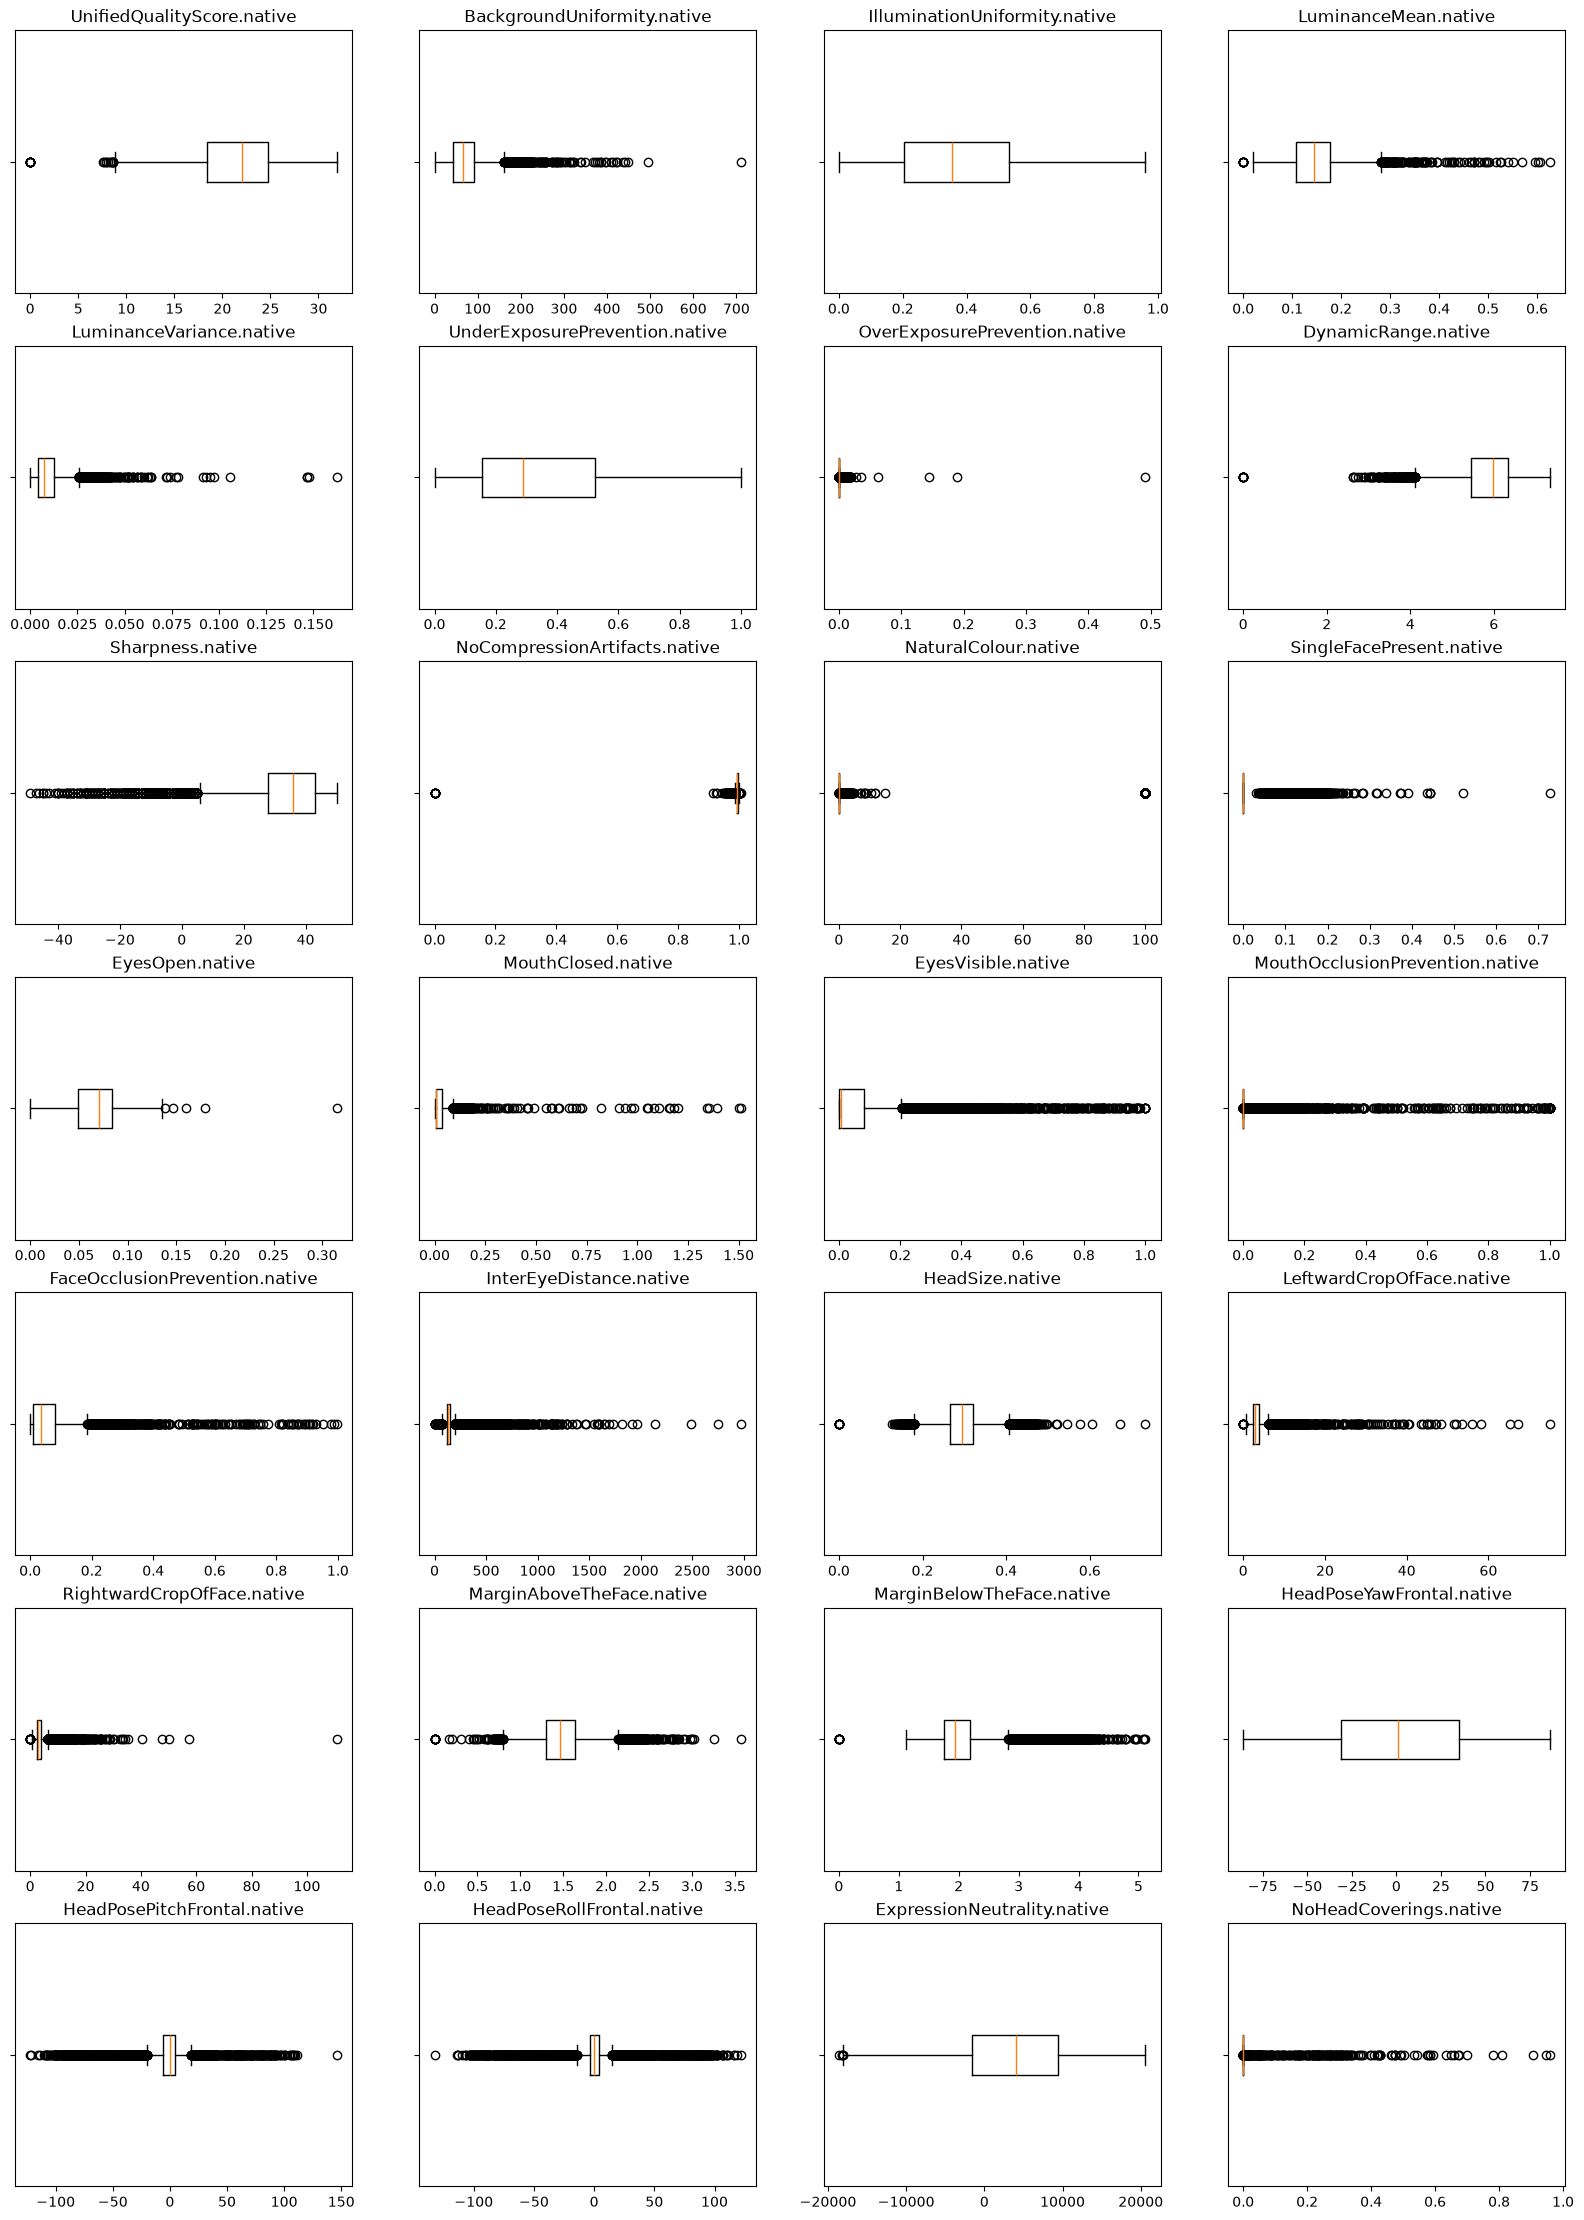

In [37]:
whisker_and_box_diagram(native)

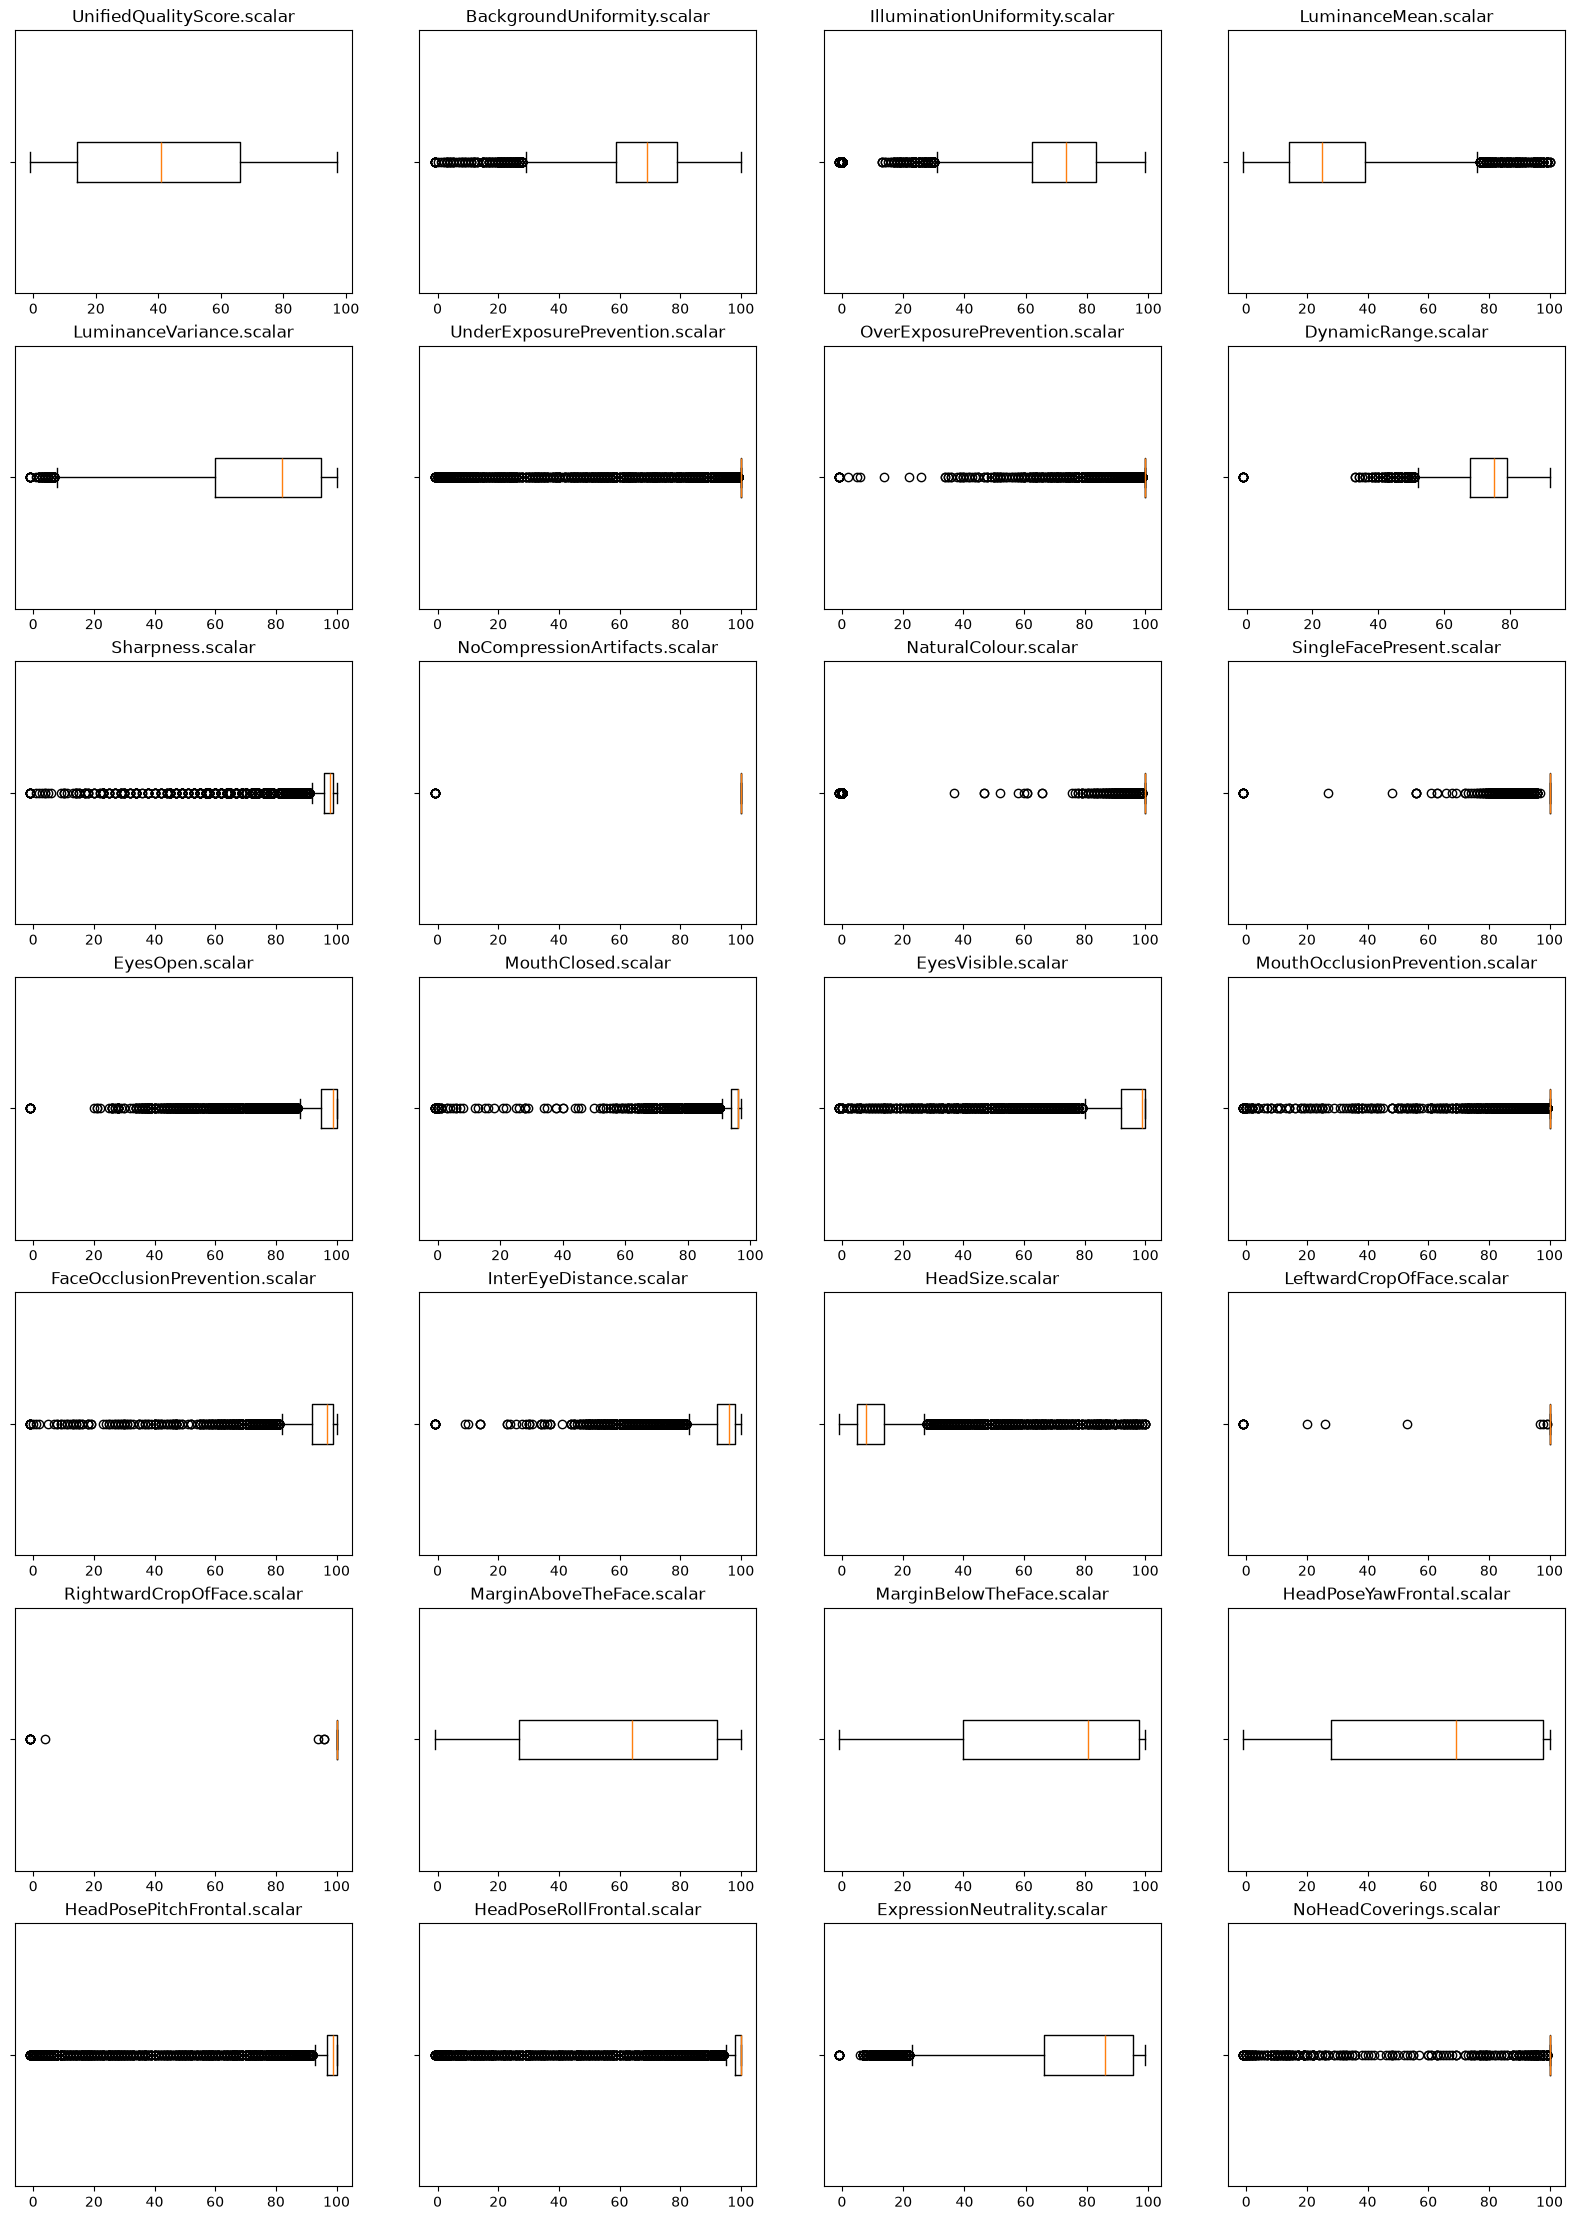

In [39]:
whisker_and_box_diagram(scalar)

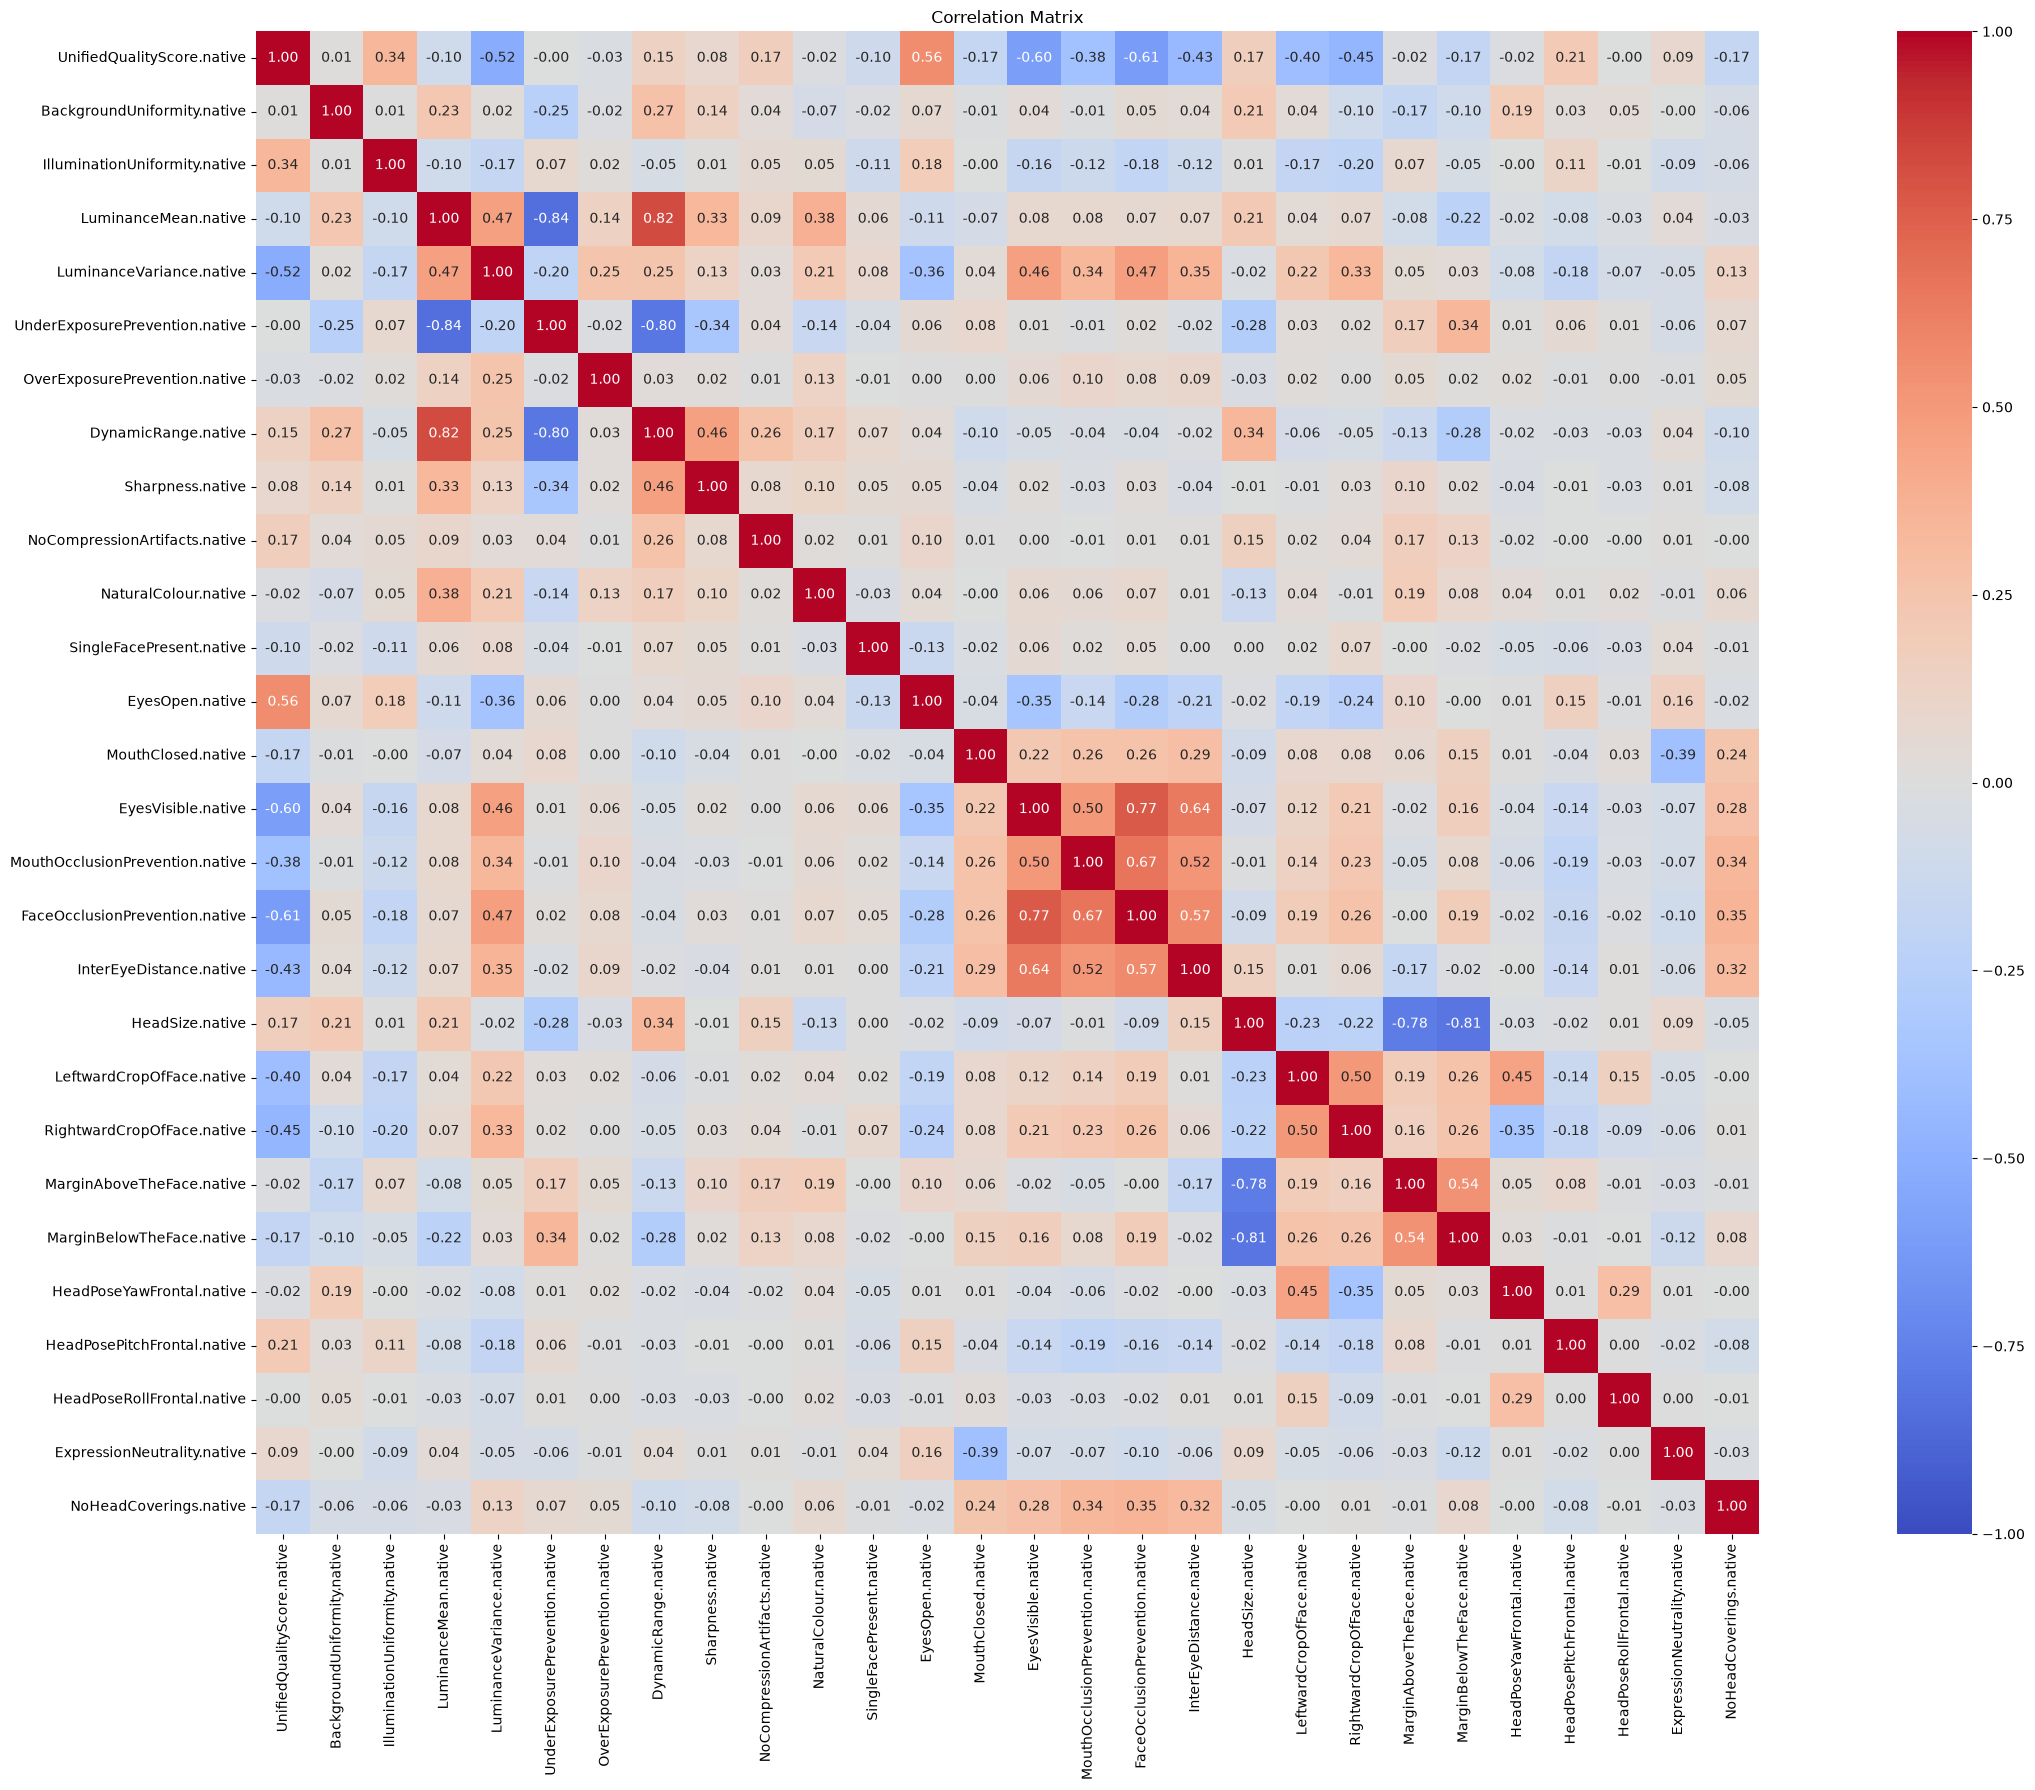

In [21]:
num_df = native.select(cs.numeric())
corr_df = num_df.corr()

corr_pd = corr_df.to_pandas()
corr_pd.index = corr_pd.columns   # le righe prendono i nomi delle colonne

plt.figure(figsize=(28, 18))
sns.heatmap(
    corr_pd,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True,
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [22]:
def _values(df, col):
    s = df[col]
    arr = s.to_numpy() if hasattr(s, "to_numpy") else np.asarray(s)
    x = np.asarray(arr, dtype=float)
    x = x[~np.isnan(x)]
    return x[x != -1]                                  # scarta i codici di errore


def hist_df(df, cols=None, percentili=(5, 10, 25, 50, 75), bins=40,
            clip=None, log_y=False, n_col=4):
    if cols is None:
        cols = [c for c in df.columns if str(c).endswith((".scalar", ".native"))] or list(df.columns)
    n_row = math.ceil(len(cols) / n_col)
    fig, axes = plt.subplots(n_row, n_col, figsize=(5 * n_col, 3.5 * n_row), squeeze=False)
    axes = axes.flatten()
    colori = plt.cm.viridis(np.linspace(0.15, 0.85, len(percentili)))

    for ax, c in zip(axes, cols):
        x = _values(df, c)
        if len(x) == 0:
            ax.set_title(f"{c} (vuota)", fontsize=9)
            continue
        rng = clip if clip is not None else tuple(np.percentile(x, [0, 100]))
        if rng[0] == rng[1]:
            rng = (rng[0] - 0.5, rng[1] + 0.5)
        ax.hist(x, bins=bins, range=rng, edgecolor="white", linewidth=0.4, color="#4C78A8")
        for p, q, col in zip(percentili, np.percentile(x, percentili), colori):
            ax.axvline(q, color=col, linestyle="--", linewidth=1.4, label=f"P{p}={q:.2f}")
        if log_y:
            ax.set_yscale("log")
        ax.set_title(str(c), fontsize=9)
        ax.legend(fontsize=7)

    for ax in axes[len(cols):]:
        ax.set_visible(False)
    fig.tight_layout()
    return fig

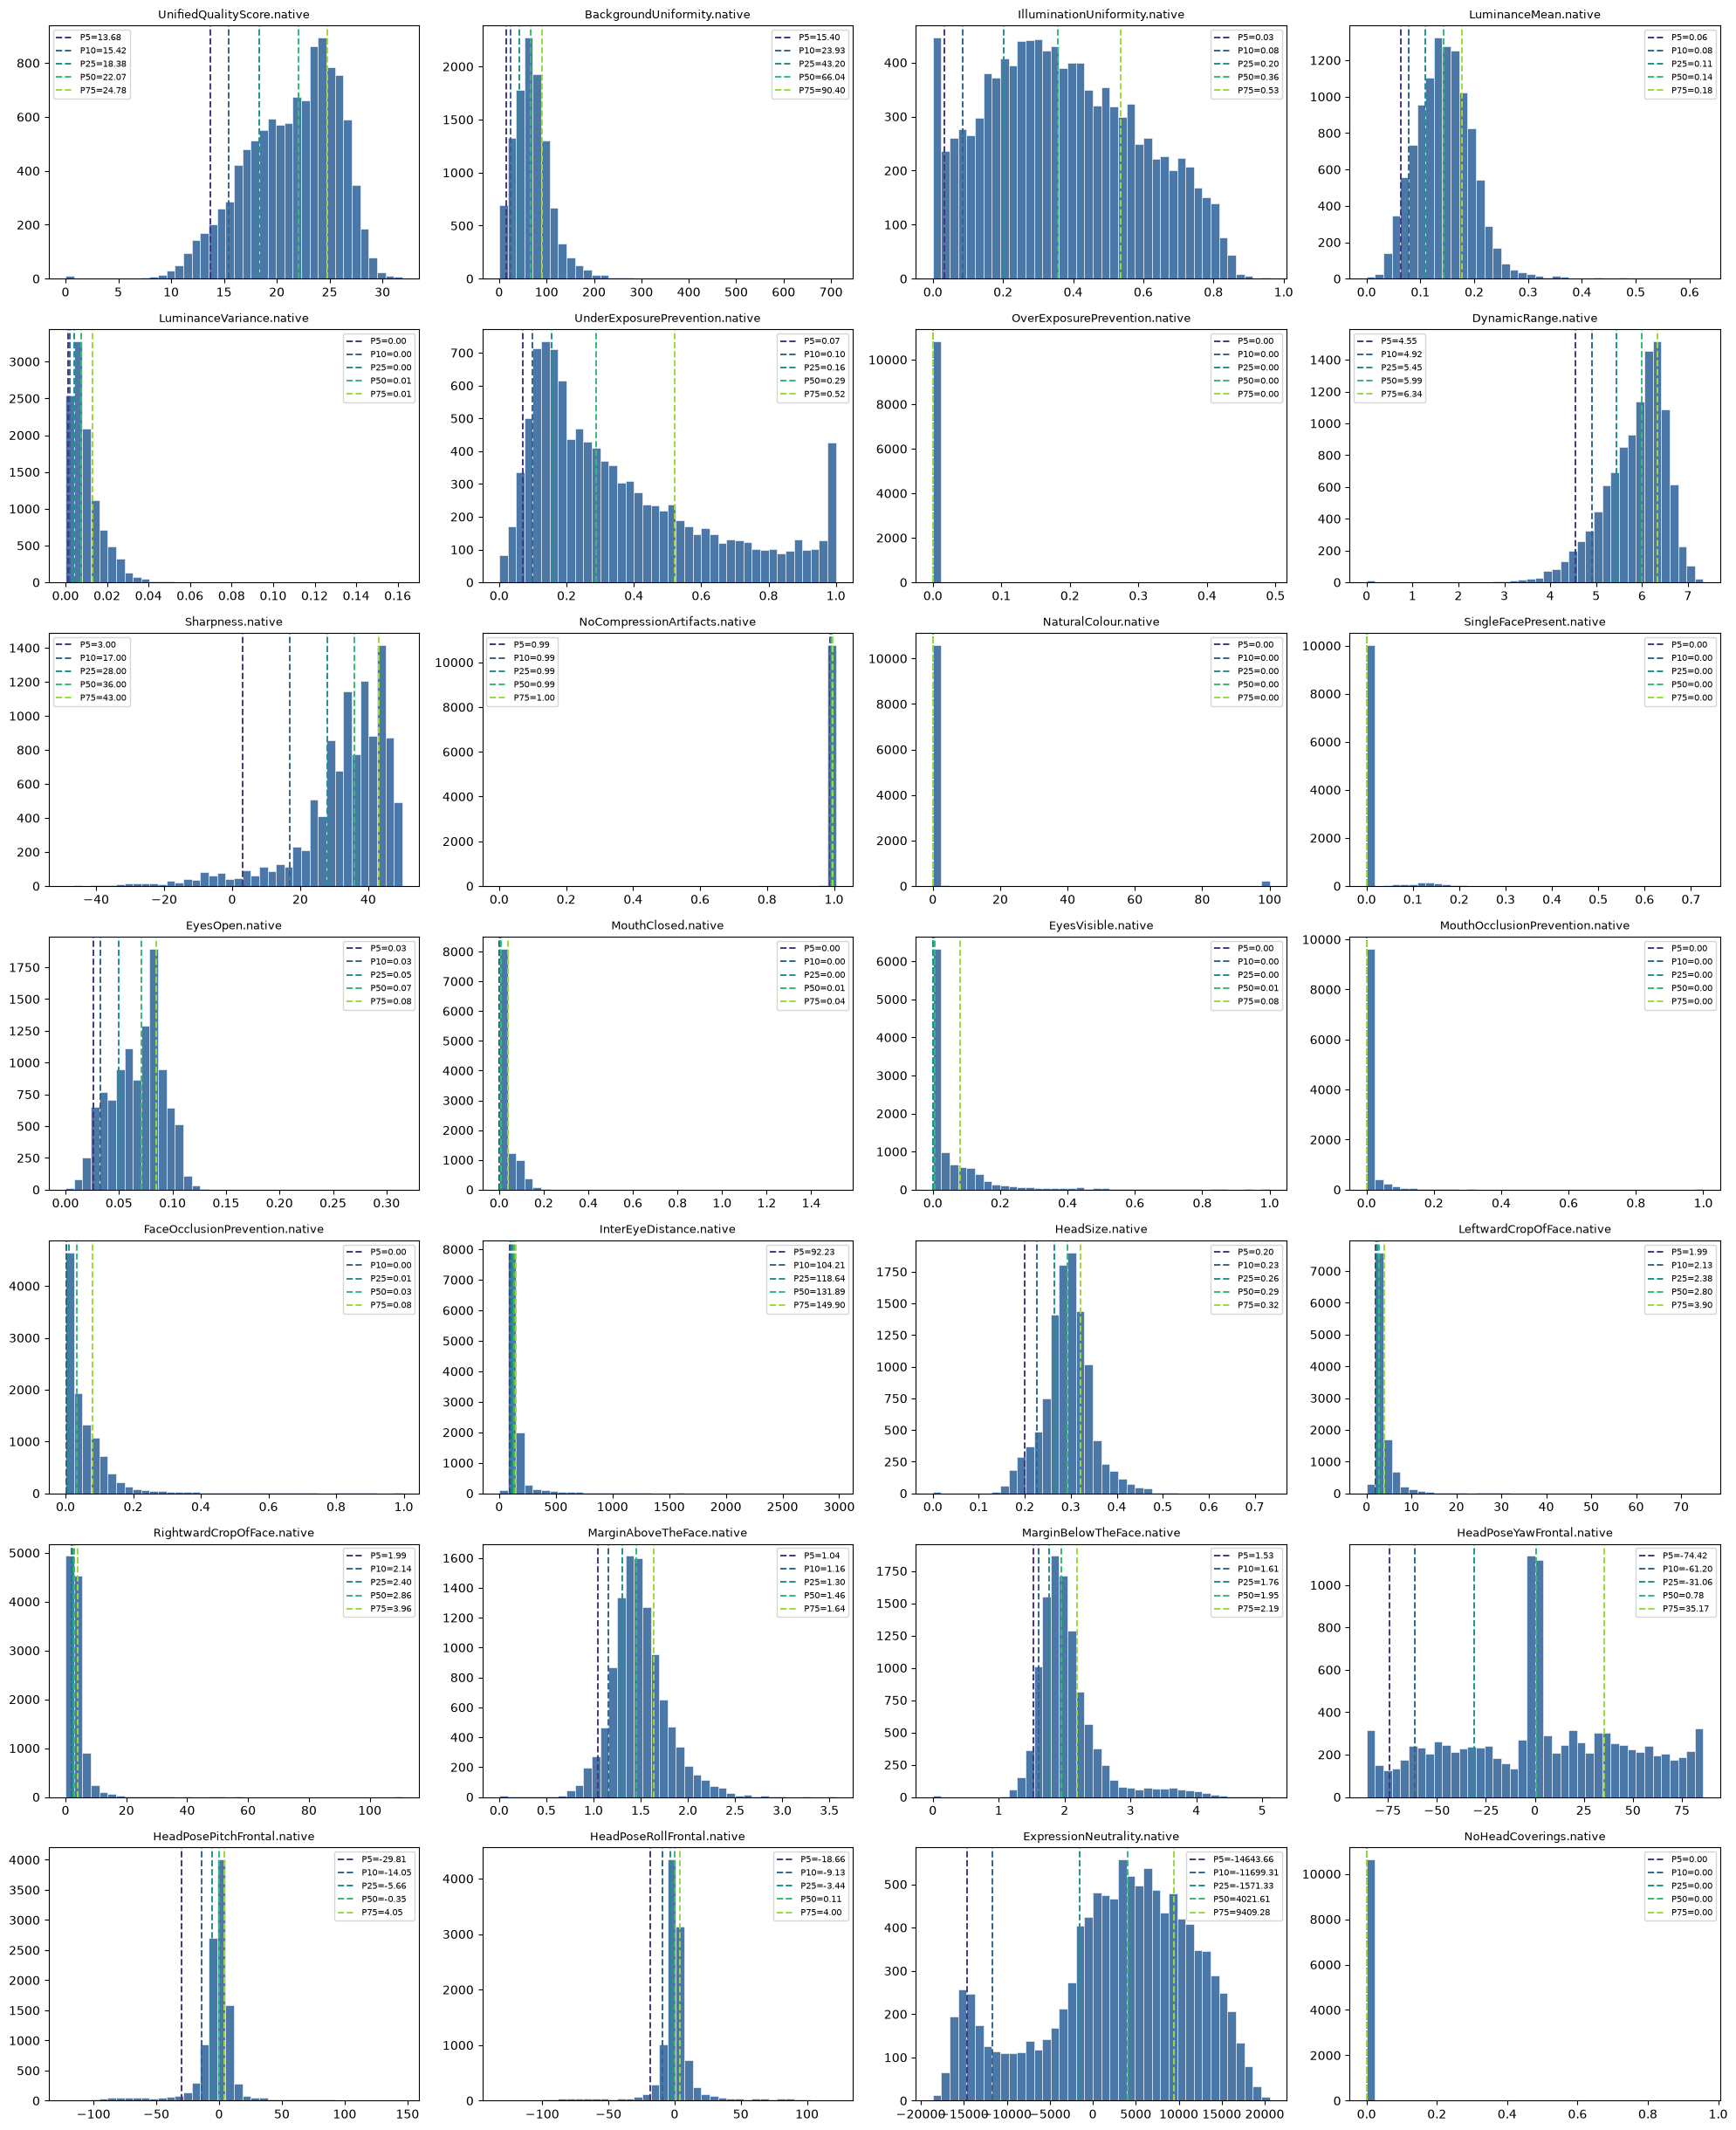

In [23]:
fig = hist_df(native)

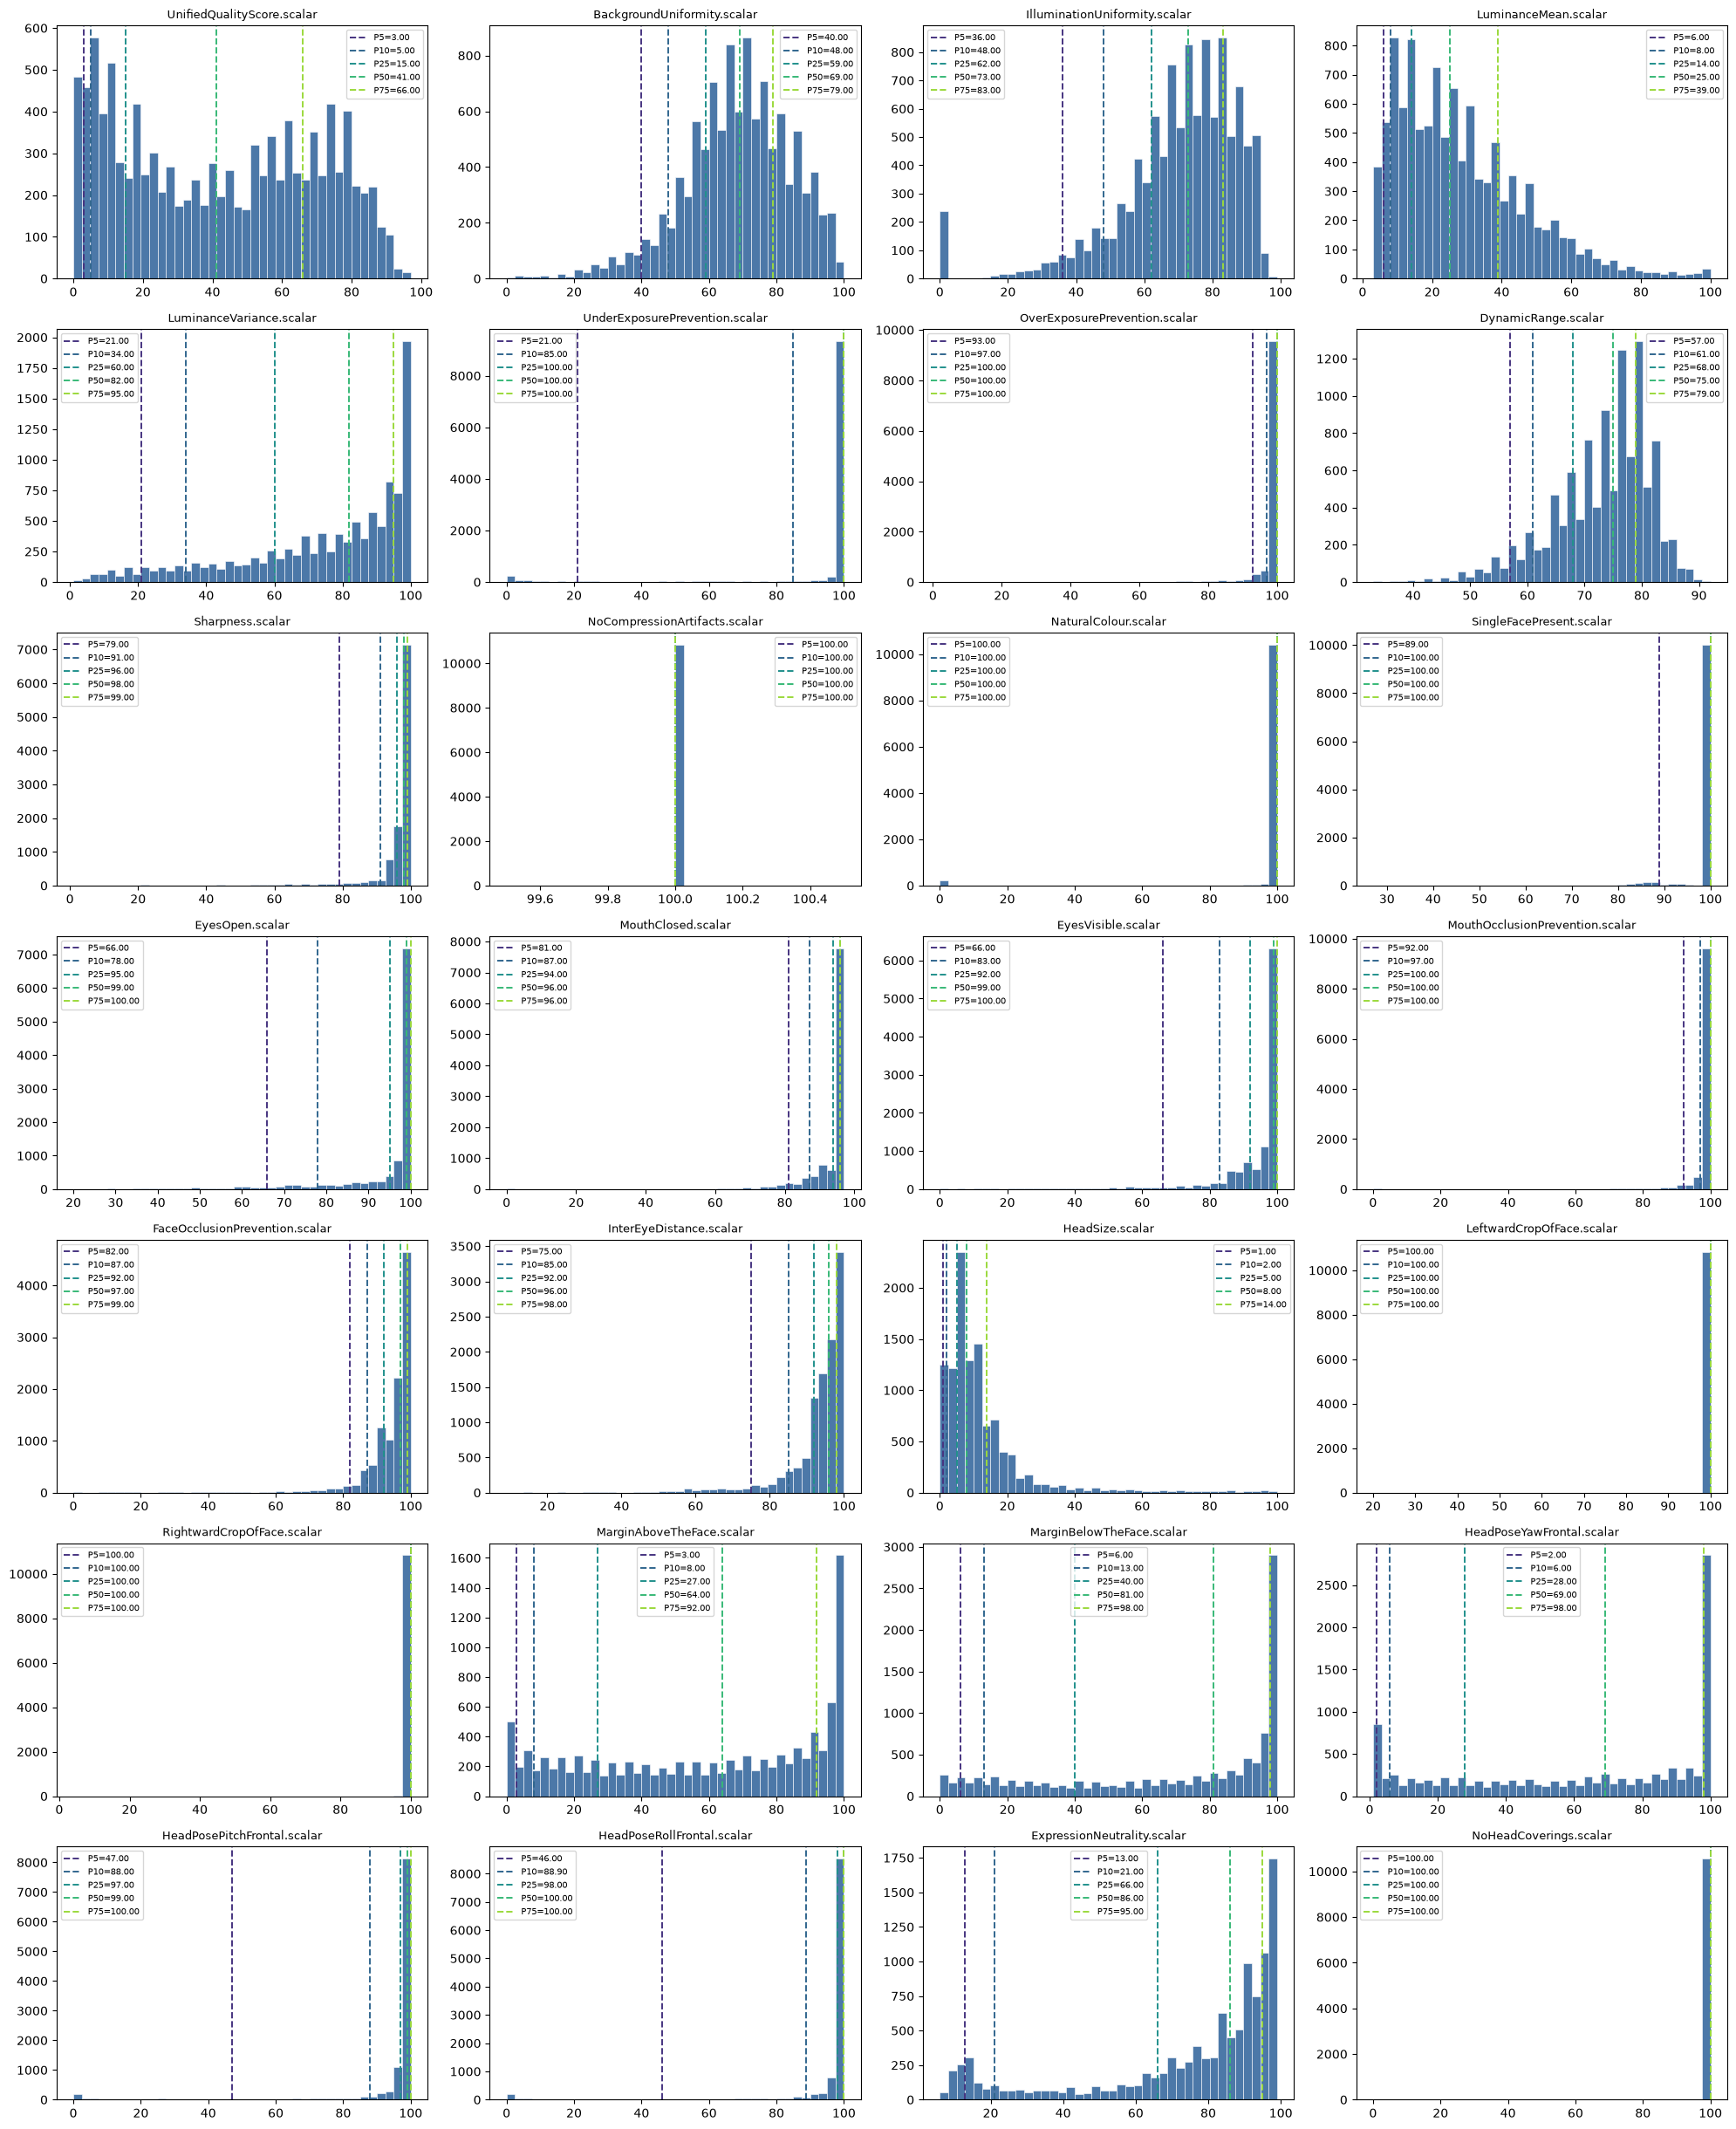

In [38]:
fig = hist_df(scalar)

#### FERET recordings and manifest

In [24]:
dvd_recordings_path = Path('../data/feret/dvd1_recordings.csv')

dvd = pl.read_csv(
    dvd_recordings_path,
    separator = ',',
    infer_schema_length=None
)

dvd.head(5)

id,URL_root,URL_relative,CaptureDate,CaptureTime,Format_value,Format_scanning,Format_compression,Subject_id,Subject_Application_Face_Pose_name,Subject_Application_Face_Pose_yaw,Subject_Application_Face_Pose_pitch,Subject_Application_Face_Pose_roll,Subject_Application_Face_Wearing_glasses,Subject_Application_Face_Hair_beard,Subject_Application_Face_Hair_mustache,Subject_Application_Face_Hair_source,Subject_Application_Face_Expression_name,Subject_Stage_id,Collection_id,Environment_id,Sensor_id,Illuminant_id,Weather_condition,Subject_Application_Face_LeftEye_x,Subject_Application_Face_LeftEye_y,Subject_Application_Face_RightEye_x,Subject_Application_Face_RightEye_y,Subject_Application_Face_Nose_x,Subject_Application_Face_Nose_y,Subject_Application_Face_Mouth_x,Subject_Application_Face_Mouth_y
str,str,str,str,str,str,str,str,str,str,f64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,i64,i64,i64,i64,i64,i64,i64,i64
"""cfrR00001""","""Disc1""","""data/images/00001/00001_930831…","""08/31/1993""","""00:00:00""","""ppm""","""Progressive""","""bzip2""","""cfrS00001""","""hl""",67.5,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""other""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",null,null,null,null,null,null,null,null
"""cfrR00002""","""Disc1""","""data/images/00001/00001_930831…","""08/31/1993""","""00:00:00""","""ppm""","""Progressive""","""bzip2""","""cfrS00001""","""fa""",0.0,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""fa""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",326,332,202,334,268,404,266,468
"""cfrR00003""","""Disc1""","""data/images/00001/00001_930831…","""08/31/1993""","""00:00:00""","""ppm""","""Progressive""","""bzip2""","""cfrS00001""","""fb""",0.0,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""fb""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",328,324,204,328,270,392,272,460
"""cfrR00004""","""Disc1""","""data/images/00001/00001_930831…","""08/31/1993""","""00:00:00""","""ppm""","""Progressive""","""bzip2""","""cfrS00001""","""hr""",-67.5,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""other""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",null,null,null,null,null,null,null,null
"""cfrR00005""","""Disc1""","""data/images/00001/00001_930831…","""08/31/1993""","""00:00:00""","""ppm""","""Progressive""","""bzip2""","""cfrS00001""","""pr""",-90.0,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""other""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",null,null,null,null,null,null,null,null


In [25]:
manifest_path = Path('../data/feret/manifest.csv')

manifest = pl.read_csv(
    manifest_path,
    separator=',',
    infer_schema_length=None
)

manifest.head(5)

shard,file,id,date,pose,flag,stem,src
str,str,i64,i64,str,str,str,str
"""shard_00000""","""00001_930831_fa_a.png""",1,930831,"""fa""","""a""","""00001_930831_fa_a""","""/datasets/Feret/dvd1/data/imag…"
"""shard_00000""","""00001_930831_fb_a.png""",1,930831,"""fb""","""a""","""00001_930831_fb_a""","""/datasets/Feret/dvd1/data/imag…"
"""shard_00000""","""00001_930831_hl_a.png""",1,930831,"""hl""","""a""","""00001_930831_hl_a""","""/datasets/Feret/dvd1/data/imag…"
"""shard_00000""","""00001_930831_hr_a.png""",1,930831,"""hr""","""a""","""00001_930831_hr_a""","""/datasets/Feret/dvd1/data/imag…"
"""shard_00000""","""00001_930831_pr_a.png""",1,930831,"""pr""","""a""","""00001_930831_pr_a""","""/datasets/Feret/dvd1/data/imag…"


In [26]:
def base_source(col):
    return pl.col(col).str.split('/').list.last().str.split('.').list.first()

In [27]:
dvdm = dvd.join_where(
    manifest.select(
        'file'
    ),
    base_source('URL_relative') == base_source('file')
)

column_to_drop = [
    'id',
    'URL_root',
    'URL_relative',
    'CaptureTime',
    'Format_value',
    'Format_scanning',
    'Format_compression',
    'Subject_id',
    'Subject_Application_Face_Pose_name',
    'CaptureDate'
]

dvdm = dvdm.drop(column_to_drop)
dvdm.head(5)

Subject_Application_Face_Pose_yaw,Subject_Application_Face_Pose_pitch,Subject_Application_Face_Pose_roll,Subject_Application_Face_Wearing_glasses,Subject_Application_Face_Hair_beard,Subject_Application_Face_Hair_mustache,Subject_Application_Face_Hair_source,Subject_Application_Face_Expression_name,Subject_Stage_id,Collection_id,Environment_id,Sensor_id,Illuminant_id,Weather_condition,Subject_Application_Face_LeftEye_x,Subject_Application_Face_LeftEye_y,Subject_Application_Face_RightEye_x,Subject_Application_Face_RightEye_y,Subject_Application_Face_Nose_x,Subject_Application_Face_Nose_y,Subject_Application_Face_Mouth_x,Subject_Application_Face_Mouth_y,file
f64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,i64,i64,i64,i64,i64,i64,i64,i64,str
67.5,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""other""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",null,null,null,null,null,null,null,null,"""00001_930831_hl_a.png"""
0.0,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""fa""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",326,332,202,334,268,404,266,468,"""00001_930831_fa_a.png"""
0.0,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""fb""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",328,324,204,328,270,392,272,460,"""00001_930831_fb_a.png"""
-67.5,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""other""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",null,null,null,null,null,null,null,null,"""00001_930831_hr_a.png"""
-90.0,0,0,"""Yes""","""No""","""No""","""Retrospectively""","""other""","""cfrT00001""","""cfrC00001""","""cfrE00001""","""cfrN00002""","""cfrI00003""","""Inside""",null,null,null,null,null,null,null,null,"""00001_930831_pr_a.png"""


#### Boolean Glasses with OFIQ score

In [28]:
with_glasses_raw = df.select([
    'EyesVisible.native',
    'FaceOcclusionPrevention.native',
    'EyesOpen.native',
    'OverExposurePrevention.native',
    'ExpressionNeutrality.native',
    'Filename'
]).join_where(
    dvdm.select([
        'Subject_Application_Face_Wearing_glasses',
        'file'
    ]).filter(
        pl.col('Subject_Application_Face_Wearing_glasses') == "Yes"
    ),
    base_source('Filename') == base_source('file')
)

with_glasses = with_glasses_raw.drop([
    'Subject_Application_Face_Wearing_glasses',
    'file',
    'Filename'
])
with_glasses.head(5)

EyesVisible.native,FaceOcclusionPrevention.native,EyesOpen.native,OverExposurePrevention.native,ExpressionNeutrality.native
f64,f64,f64,f64,f64
0.007738,0.101598,0.082547,0.0,9588.507812
0.43986,0.088259,0.029122,0.00007,771.837036
0.0,0.092016,0.056564,0.0,274.93045
0.546468,0.124212,0.037296,0.000475,5923.575195
0.509339,0.117769,0.04949,0.000502,-1258.674316


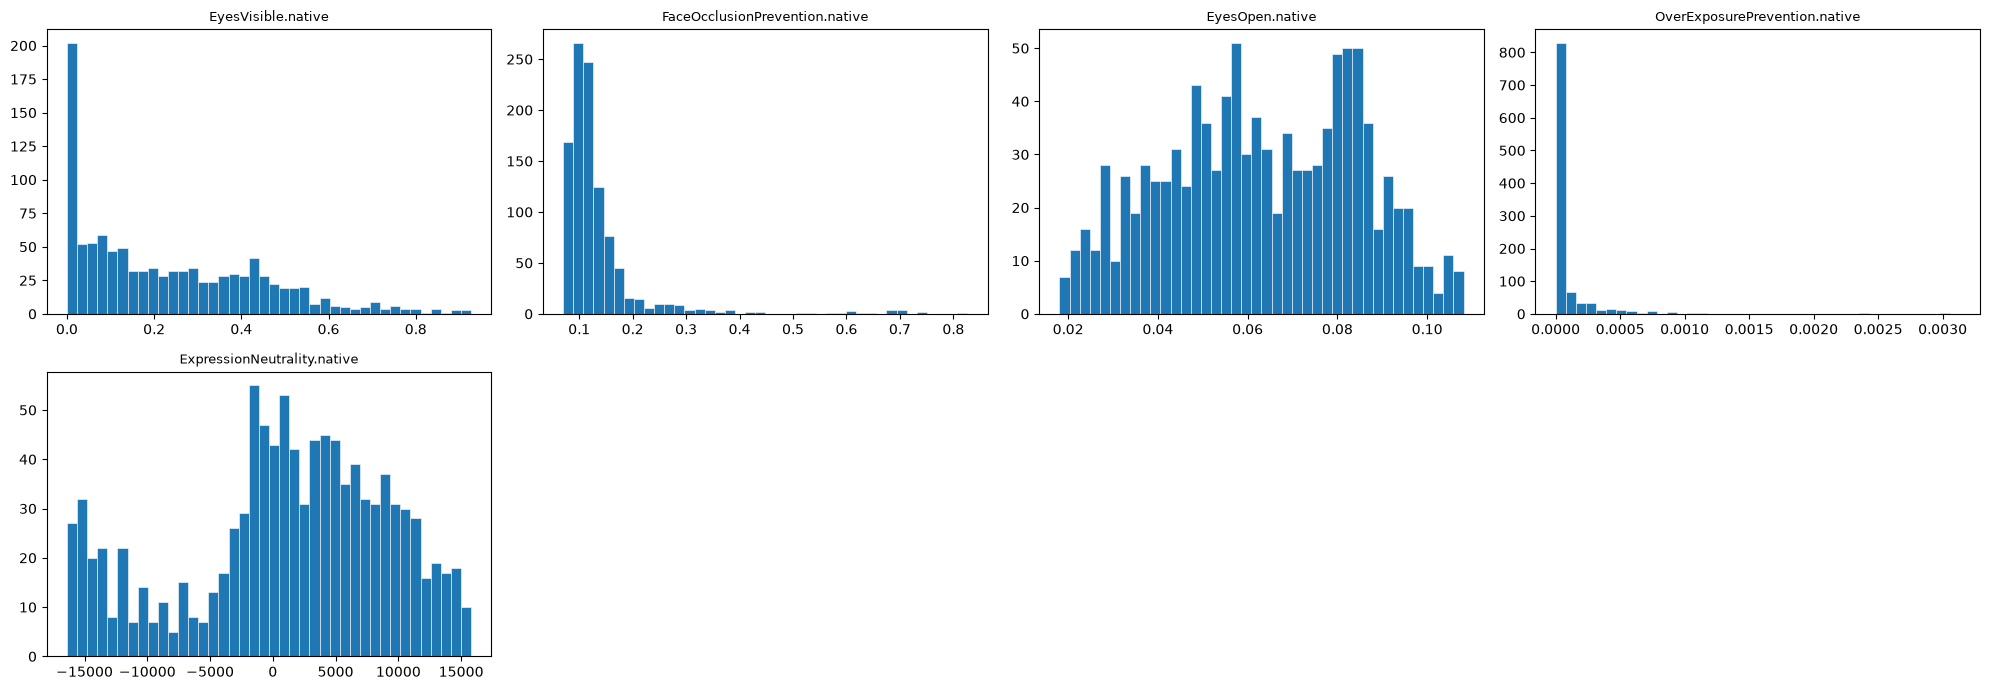

In [29]:
create_histograms(with_glasses);

In [30]:
without_glasses_raw = df.select([
    'EyesVisible.native',
    'FaceOcclusionPrevention.native',
    'EyesOpen.native',
    'OverExposurePrevention.native',
    'ExpressionNeutrality.native',
    'Filename'
]).join_where(
    dvdm.select([
        'Subject_Application_Face_Wearing_glasses',
        'file'
    ]).filter(
        pl.col('Subject_Application_Face_Wearing_glasses') == "No"
    ),
     base_source('Filename') == base_source('file')
)

without_glasses = without_glasses_raw.drop([
    'Subject_Application_Face_Wearing_glasses',
    'file',
    'Filename'
])
print(without_glasses.height)
without_glasses.head(5)

9791


EyesVisible.native,FaceOcclusionPrevention.native,EyesOpen.native,OverExposurePrevention.native,ExpressionNeutrality.native
f64,f64,f64,f64,f64
0.098837,0.168938,0.037622,0.000301,2455.544678
0.0,0.00343,0.103142,0.000015,5207.723633
0.000964,0.078137,0.109179,0.000039,4639.0
0.0,0.006801,0.102304,0.0,-12382.645508
0.0,0.000888,0.085213,0.000036,18748.015625


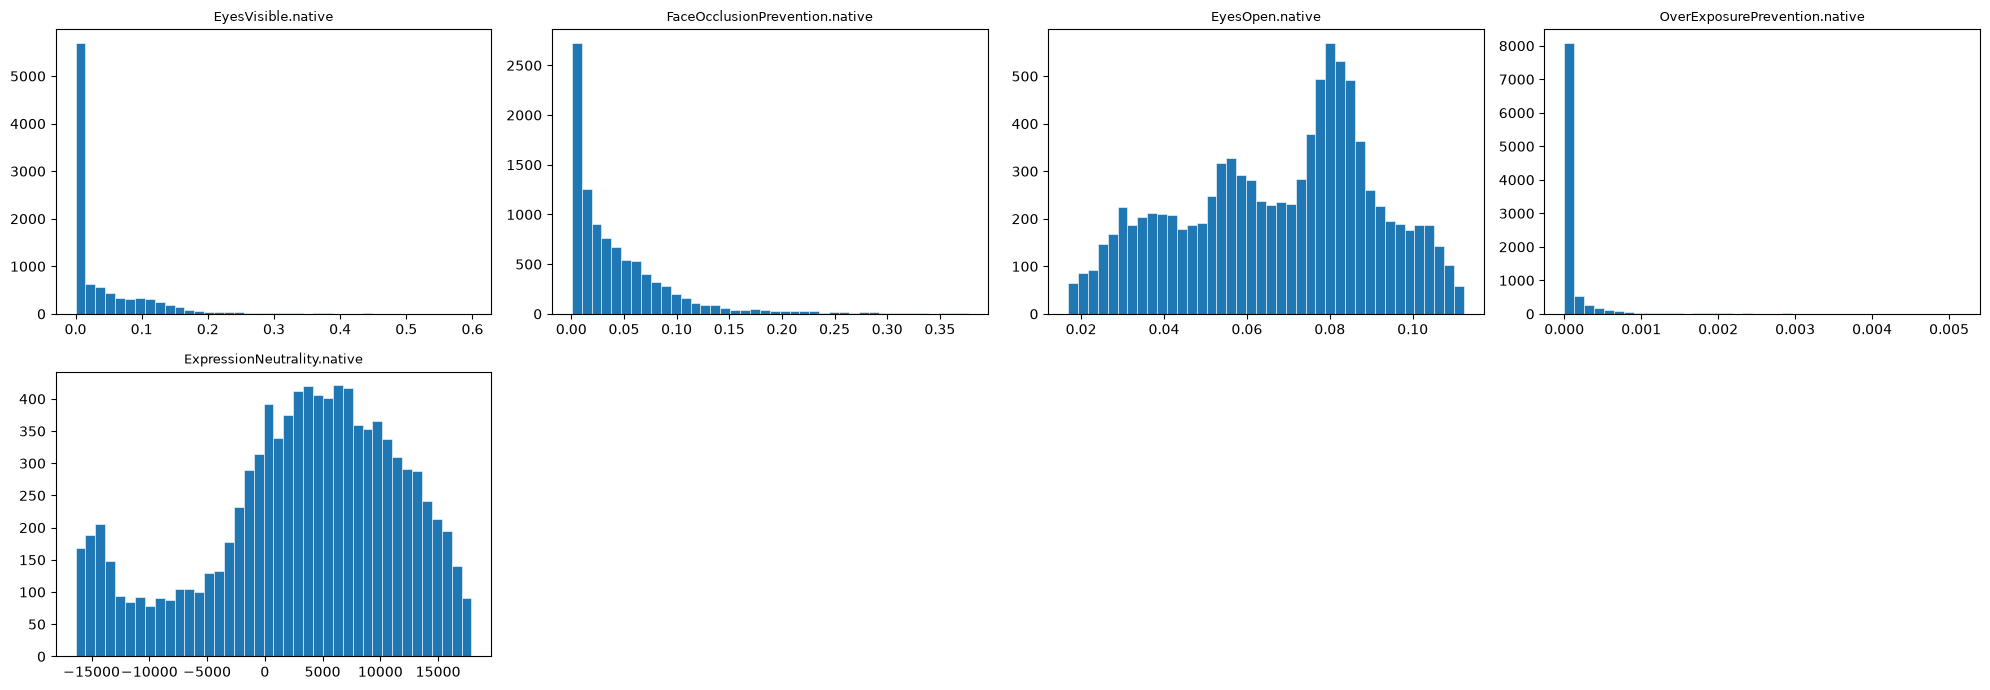

In [31]:
create_histograms(without_glasses);

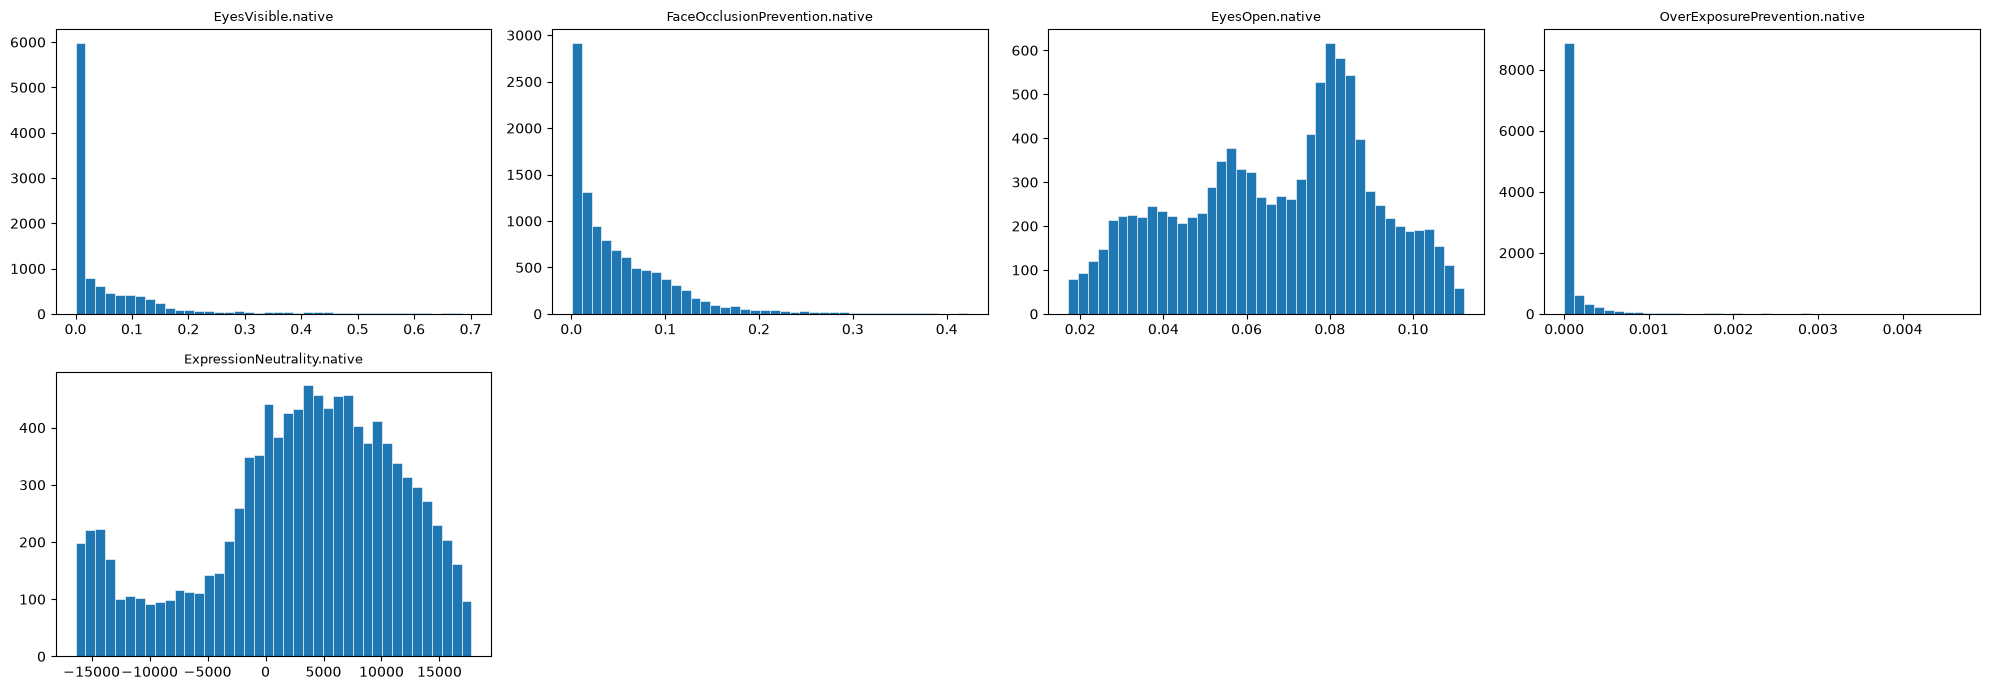

In [32]:
columns = [
    'EyesVisible.native',
    'FaceOcclusionPrevention.native',
    'EyesOpen.native',
    'OverExposurePrevention.native',
    'ExpressionNeutrality.native'
]
f = native.select(columns)
create_histograms(f);

In [33]:
def smd_pl(a, b, name):
    rows = []
    for c in a.columns:
        x = a[c].filter(a[c].is_not_null() & (a[c] != -1))     
        y = b[c].filter(b[c].is_not_null() & (b[c] != -1))
        s = pl.concat([x, y]).std()
        rows.append((c, (x.mean() - y.mean()) / s if s else None))
    return pl.DataFrame(rows, schema=["component", name], orient="row")

In [34]:
M = smd_pl(with_glasses, without_glasses, "glasses")
M

component,glasses
str,f64
"""EyesVisible.native""",1.449174
"""FaceOcclusionPrevention.native""",1.084088
"""EyesOpen.native""",-0.17938
"""OverExposurePrevention.native""",0.065413
"""ExpressionNeutrality.native""",-0.236965


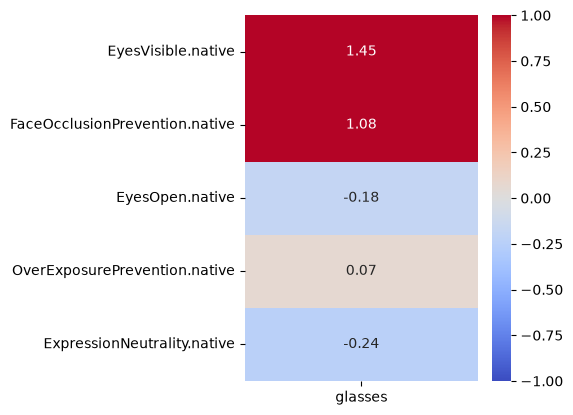

In [35]:
attrs = [c for c in M.columns if c != "component"]

fig, ax = plt.subplots(figsize=(1.6 * len(attrs) + 4, 0.45 * M.height + 2))
sns.heatmap(
    M.select(attrs).fill_null(float("nan")).to_numpy(),
    annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
    xticklabels=attrs, yticklabels=M["component"].to_list(), ax=ax,
)
fig.tight_layout()

#### Prompt

In [53]:
prompt_path = Path('../data/feret/prompt/prompt_feret_soglie_glint.csv')
prompt = pl.read_csv(
    prompt_path,
    separator=','
)
pl.Config.set_fmt_str_lengths(1000)
pl.Config.set_tbl_cols(-1)


prompt

file,split,issues,good,issues_list,good_list,prompt
str,str,str,str,str,str,str
"""00266_940128_pl.png""","""test""","""eyes closed or mostly closed; slightly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head too small in the frame""","""proper space above the head; proper space below the face""","""[""eyes closed or mostly closed"", ""slightly non-neutral expression"", ""partial head covering"", ""cluttered, non-uniform background"", ""slightly uneven lighting"", ""image clearly too dark or too bright"", ""head too small in the frame""]""","""[""proper space above the head"", ""proper space below the face""]""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; slightly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head too small in the frame Good aspects: proper space above the head; proper space below the face"""
"""00170_931230_pl.png""","""test""","""eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame""","""no head covering; proper space above the head; proper space below the face""","""[""eyes partly closed"", ""slightly uneven background"", ""strongly uneven lighting on the face"", ""image clearly too dark or too bright"", ""head too small in the frame""]""","""[""no head covering"", ""proper space above the head"", ""proper space below the face""]""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: no head covering; proper space above the head; proper space below the face"""
"""00445_940422_pl.png""","""test""","""eyes closed or mostly closed; clearly non-neutral expression; partial head covering; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame""","""uniform background; proper space above the head; proper space below the face""","""[""eyes closed or mostly closed"", ""clearly non-neutral expression"", ""partial head covering"", ""strongly uneven lighting on the face"", ""image clearly too dark or too bright"", ""head too small in the frame""]""","""[""uniform background"", ""proper space above the head"", ""proper space below the face""]""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; partial head covering; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: uniform background; proper space above the head; proper space below the face"""
"""00552_940519_ql.png""","""test""","""partial head covering; slightly uneven background; image clearly too dark or too bright; head too small in the frame""","""eyes open; neutral expression; even lighting on the face; proper space above the head; proper space below the face""","""[""partial head covering"", ""slightly uneven background"", ""image clearly too dark or too bright"", ""head too small in the frame""]""","""[""eyes open"", ""neutral expression"", ""even lighting on the face"", ""proper space above the head"", ""proper space below the face""]""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; slightly uneven background; image clearly too dark or

In [55]:
prompt.select(["file", "issues", "good", "prompt"]).head(10)

file,issues,good,prompt
str,str,str,str
"""00266_940128_pl.png""","""eyes closed or mostly closed; slightly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head too small in the frame""","""proper space above the head; proper space below the face""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; slightly non-neutral expression; partial head covering; cluttered, non-uniform background; slightly uneven lighting; image clearly too dark or too bright; head too small in the frame Good aspects: proper space above the head; proper space below the face"""
"""00170_931230_pl.png""","""eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame""","""no head covering; proper space above the head; proper space below the face""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes partly closed; slightly uneven background; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: no head covering; proper space above the head; proper space below the face"""
"""00445_940422_pl.png""","""eyes closed or mostly closed; clearly non-neutral expression; partial head covering; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame""","""uniform background; proper space above the head; proper space below the face""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: eyes closed or mostly closed; clearly non-neutral expression; partial head covering; strongly uneven lighting on the face; image clearly too dark or too bright; head too small in the frame Good aspects: uniform background; proper space above the head; proper space below the face"""
"""00552_940519_ql.png""","""partial head covering; slightly uneven background; image clearly too dark or too bright; head too small in the frame""","""eyes open; neutral expression; even lighting on the face; proper space above the head; proper space below the face""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head covering; slightly uneven background; image clearly too dark or too bright; head too small in the frame Good aspects: eyes open; neutral expression; even lighting on the face; proper space above the head; proper space below the face"""
"""00505_940519_ql.png""","""slightly non-neutral expression; partial head covering; slightly uneven lighting; image slightly too dark or bright; head too small in the frame""","""eyes open; uniform background; proper space above the head; proper space below the face""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: slightly non-neutral expression; partial head covering; slightly uneven lighting; image slightly too dark or bright; head too small in the frame Good aspects: eyes open; uniform background; proper space above the head; proper space below the face"""
"""00347_940422_fb.png""","""partial head covering; cluttered, non-uniform background; image clearly too dark or too bright; head too small in the frame""","""eyes open; even lighting on the face; proper space above the head; proper space below the face""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers or add other details. Issues: partial head

In [54]:
df.head(1)

Filename,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native,UnifiedQualityScore.scalar,BackgroundUniformity.scalar,IlluminationUniformity.scalar,LuminanceMean.scalar,LuminanceVariance.scalar,UnderExposurePrevention.scalar,OverExposurePrevention.scalar,DynamicRange.scalar,Sharpness.scalar,NoCompressionArtifacts.scalar,NaturalColour.scalar,SingleFacePresent.scalar,EyesOpen.scalar,MouthClosed.scalar,EyesVisible.scalar,MouthOcclusionPrevention.scalar,FaceOcclusionPrevention.scalar,InterEyeDistance.scalar,HeadSize.scalar,LeftwardCropOfFace.scalar,RightwardCropOfFace.scalar,MarginAboveTheFace.scalar,MarginBelowTheFace.scalar,HeadPoseYawFrontal.scalar,HeadPosePitchFrontal.scalar,HeadPoseRollFrontal.scalar,ExpressionNeutrality.scalar,NoHeadCoverings.scalar,assessment_time_in_ms,
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str
"""/home/vramos/prove/feret_all/images/shard_00000/00266_940128_pl.png""",16.760118,25.646843,0.237654,0.130497,0.023341,0.37979,0.000301,5.577375,23.0,0.994593,0.0,0.076084,0.037622,0.012371,0.098837,0.001256,0.168938,126.571378,0.235358,3.490909,6.818182,1.626097,2.621667,-64.244137,-1.147325,3.250027,2455.544678,0.0,8,88,65,20,97,100,97,70,95,100,100,92,85,96,90,100,83,94,3,100,100,91,100,19,100,100,82,100,630,null


In [ ]:
import base64
from pathlib import Path
from IPython.display import HTML, display

def img_as_tag(file_name, cartella, dimensione=100):
    img_path = Path(cartella) / file_name
    encoded = base64.b64encode(img_path.read_bytes()).decode("ascii")
    return f'<img src="data:image/jpeg;base64,{encoded}" width="{dimensione}">'

tabella_html = tabella.reset_index()
tabella_html["immagine"] = tabella_html["immagine"].apply(
    lambda nome: img_as_tag(nome, cartella_immagini, 100)
)

display(HTML(tabella_html.to_html(escape=False, index=False)))